# Turbulence Super-Resolution — Training Notebook

## Setup and Imports

In [1]:
import sys
from pathlib import Path

def find_project_root(start: Path, target="models", max_up: int = 8) -> Path:
    root = start.resolve()
    for _ in range(max_up):
        if (root / target).exists():
            return root
        if root.parent == root:
            break
        root = root.parent
    raise FileNotFoundError(f"Could not find '{target}' above {start}")


ROOT = find_project_root(Path.cwd())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

NCCL_SHM_DISABLE=1 

from datetime import datetime
from contextlib import nullcontext
import json
import warnings
import h5py
import yaml
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from tqdm.notebook import tqdm

from utils.experiment_manager import ExperimentManager
from utils.sr_datasets import (
    TemporalStackDataset,
    MultiFieldDataset,
    create_snapshot_splits,
    compute_global_stats,
    compute_multifield_stats,
)
from utils.losses import GradientLoss, SpectralLoss, RelativisticAverageGANLoss
from utils.physics_losses import PhysicsInformedLoss, compute_vorticity_from_velocity
from utils.metrics import psnr, ssim
from utils.physics import (
    compute_vorticity_2d,
    gradient_magnitude_2d,
    laplacian_2d,
    advection_u_dot_grad_omega,
    energy_spectrum_2d,
    pdf_from_field,
)
from models.factory import build_model_from_config, available_models
from models.SR.esrgan import ESRGANDiscriminator

plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 150
plt.rcParams['figure.facecolor'] = 'white'
np.random.seed(42)
torch.manual_seed(42)
warnings.filterwarnings('ignore')

print(f"Project root: {ROOT}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Registered models: {available_models()}")

Project root: /workspaces/jhtdb-ml
PyTorch version: 2.9.0+cu128
CUDA available: True
Registered models: ('edsr', 'esrgan', 'hdsc_ms', 'mlp', 'unet', 'unet_meteo')


## Configuration and Workspace

In [20]:
CONFIG_PATH = ROOT / 'configs/sr_esrgan_128.yaml'  # ← update as needed
with open(CONFIG_PATH) as fp:
    config = yaml.safe_load(fp)

print('Configuration loaded from:', CONFIG_PATH)
print(json.dumps({
    'experiment': config['experiment']['name'],
    'model': config['model']['architecture'],
    'component': config['data']['component'],
    'scale_factor': config['model']['scale_factor'],
    'epochs': config['training']['epochs'],
    'batch_size': config['training']['batch_size'],
    'physics_enabled': config['loss']['components'].get('physics', {}).get('enabled', False),
}, indent=2))

exp_cfg = config['experiment']
run_name = exp_cfg.get('run_name')
manager = ExperimentManager(
    task='SR',
    name=exp_cfg['name'],
    base_dir=ROOT / 'work',
    run_name=run_name
)
manager.setup()
manager.save_config(config)

ckpt_cfg = config['training'].get('checkpoints', {})
BEST_CKPT_NAME = ckpt_cfg.get('best', 'best_model.pth')
LAST_CKPT_NAME = ckpt_cfg.get('last', 'last_model.pth')

FIGURES_DIR = manager.plots_dir
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_LOG_PATH = manager.logs_dir / 'training_log.txt'
TRAIN_LOG_PATH.parent.mkdir(parents=True, exist_ok=True)
TRAIN_LOG_PATH.write_text('')

print('Working directory:', manager.run_dir)
print('  Plots:', FIGURES_DIR)
print('  Checkpoints:', manager.checkpoints_dir)
print('  Logs:', TRAIN_LOG_PATH)
if run_name:
    print(f"  (Using fixed run name: {run_name})")

Configuration loaded from: /workspaces/jhtdb-ml/configs/sr_esrgan_128.yaml
{
  "experiment": "sr_esrgan_isotropic",
  "model": "esrgan",
  "component": "omega_z",
  "scale_factor": 4,
  "epochs": 200,
  "batch_size": 32,
  "physics_enabled": true
}
Working directory: /workspaces/jhtdb-ml/work/SR/sr_esrgan_isotropic_ganOFF_physicsON
  Plots: /workspaces/jhtdb-ml/work/SR/sr_esrgan_isotropic_ganOFF_physicsON/plots
  Checkpoints: /workspaces/jhtdb-ml/work/SR/sr_esrgan_isotropic_ganOFF_physicsON/checkpoints
  Logs: /workspaces/jhtdb-ml/work/SR/sr_esrgan_isotropic_ganOFF_physicsON/logs/training_log.txt
  (Using fixed run name: sr_esrgan_isotropic_ganOFF_physicsON)


## Data Preparation

In [3]:
# Load dataset
h5_path = (ROOT / config['data']['h5_path']).resolve()
print(f"Loading data from: {h5_path}")

fields = {}
times = []
y_values = []

with h5py.File(h5_path, 'r') as h5:
    # Check structure
    top_keys = list(h5.keys())
    print(f"Top-level keys: {top_keys}")
    
    if 'snapshots' in h5:
        # Hierarchical structure
        snapshots = h5['snapshots']
        snap_keys = sorted(snapshots.keys())
        print(f"Found {len(snap_keys)} snapshots")
        
        for key in snap_keys:
            snap = snapshots[key]
            for field_name in ['ux', 'uy', 'uz', 'omega_z']:
                if field_name in snap:
                    fields.setdefault(field_name, []).append(np.asarray(snap[field_name]))
            if 'time' in snap:
                times.append(float(np.asarray(snap['time'])))
            if 'y_value' in snap:
                y_values.append(np.asarray(snap['y_value']))
    else:
        # Flat structure
        for field_name in ['ux', 'uy', 'uz', 'omega_z']:
            if field_name in h5:
                fields[field_name] = [np.asarray(h5[field_name])]
        if 'time' in h5:
            times.append(np.asarray(h5['time']))
        if 'y_value' in h5:
            y_values.append(np.asarray(h5['y_value']))

# Verify required fields
required = ['ux', 'uy', 'omega_z']
missing = [name for name in required if name not in fields]
if missing:
    raise KeyError(f"Missing required fields: {missing}. Available: {list(fields.keys())}")

# Stack into arrays
ux = np.stack(fields['ux'])
uy = np.stack(fields['uy'])
omega = np.stack(fields['omega_z'])
times = np.asarray(times) if times else np.arange(ux.shape[0])
y_values = np.asarray(y_values) if y_values else None

print(f"\nData loaded:")
print(f"  Snapshots: {ux.shape[0]}")
print(f"  Resolution: {ux.shape[1]}×{ux.shape[2]}")
print(f"  Time range: {times[0]:.3f} - {times[-1]:.3f}")
print(f"  Available components: {list(fields.keys())}")

Loading data from: /workspaces/jhtdb-ml/data/raw/isotropic_xy_128/isotropic_xy_128.h5
Top-level keys: ['snapshots']
Found 7992 snapshots

Data loaded:
  Snapshots: 7992
  Resolution: 128×128
  Time range: 0.000 - 9.990
  Available components: ['ux', 'uy', 'uz', 'omega_z']


In [4]:
# Select component for SR (from config) and store ALL fields for physics losses
component = config['data']['component']
component_map = {
    'ux': ux,
    'uy': uy,
    'omega_z': omega,
}

if component not in component_map:
    raise ValueError(f"Component '{component}' not available. Options: {list(component_map.keys())}")

hr_data = component_map[component]  # Shape: (T, 256, 256) - target field for SR

# Store ALL fields for physics-informed training
all_fields = {
    'ux': ux,
    'uy': uy,
    'omega_z': omega
}

# Get grid spacing from config (needed for physics losses)
if 'domain' in config and 'dns_info' in config['domain']:
    dx = config['domain']['dns_info']['effective_resolution']['dx']
    dy = config['domain']['dns_info']['effective_resolution']['dy']
    print(f"\nGrid spacing from config:")
    print(f"  dx = {dx:.6f}")
    print(f"  dy = {dy:.6f}")
else:
    # Fallback: estimate from data shape
    dx = dy = 1.0 / hr_data.shape[1]
    print(f"\nGrid spacing (estimated from data):")
    print(f"  dx = dy = {dx:.6f}")

print(f"\nSelected component for SR: {component}")
print(f"  Shape: {hr_data.shape}")
print(f"  Snapshots: {hr_data.shape[0]}")
print(f"  Resolution: {hr_data.shape[1]}×{hr_data.shape[2]}")
print(f"  Range: [{hr_data.min():.4f}, {hr_data.max():.4f}]")
print(f"  Mean: {hr_data.mean():.4f}, Std: {hr_data.std():.4f}")

print(f"\nAll fields loaded (for physics losses):")
for name, field in all_fields.items():
    print(f"  {name}: {field.shape}, range=[{field.min():.4f}, {field.max():.4f}]")


Grid spacing from config:
  dx = 0.006136
  dy = 0.006136

Selected component for SR: omega_z
  Shape: (7992, 128, 128)
  Snapshots: 7992
  Resolution: 128×128
  Range: [-323.4162, 309.4149]
  Mean: -0.0954, Std: 12.6199

All fields loaded (for physics losses):
  ux: (7992, 128, 128), range=[-2.6636, 2.6615]
  uy: (7992, 128, 128), range=[-3.5655, 2.6271]
  omega_z: (7992, 128, 128), range=[-323.4162, 309.4149]


## Snapshot-wise Splits and Dataset Creation

Create train/val/test splits by snapshot index (no temporal leakage).

**Two dataset options:**
1. **TemporalStackDataset** (default): Returns only selected component (omega_z)
2. **MultiFieldDataset** (physics-informed): Returns all fields (ux, uy, omega_z) for physics losses

The notebook automatically uses MultiFieldDataset when physics losses are enabled in the config.

In [5]:
# =============================================================================
# Create snapshot-wise splits (NO RANDOM SHUFFLING!)
# =============================================================================
train_idx, val_idx, test_idx = create_snapshot_splits(
    total_snapshots=hr_data.shape[0],
    train_snapshots=config['data']['split']['train_snapshots'],
    val_snapshots=config['data']['split']['val_snapshots'],
    test_snapshots=config['data']['split']['test_snapshots']
)

print("Snapshot-wise splits (temporally ordered):")
print(f"  Train: snapshots {train_idx[0]}-{train_idx[-1]} ({len(train_idx)} snapshots)")
print(f"  Val:   snapshots {val_idx[0]}-{val_idx[-1]} ({len(val_idx)} snapshots)")
print(f"  Test:  snapshots {test_idx[0]}-{test_idx[-1]} ({len(test_idx)} snapshots)")

# =============================================================================
# Check if physics-informed training is enabled
# =============================================================================
USE_PHYSICS_DATASET = config['loss']['components'].get('physics', {}).get('enabled', False)

if USE_PHYSICS_DATASET:
    print(f"\n{'='*70}")
    print("PHYSICS-INFORMED DATASET MODE")
    print(f"{'='*70}")
    print("Using MultiFieldDataset (returns ux, uy, omega_z for physics losses)")
    
    # Compute normalization stats for ALL components
    if config['data']['normalization']['method'] == 'global':
        multifield_stats = compute_multifield_stats(ux, uy, omega, train_idx)
        print(f"\nGlobal normalization stats (computed on train set only):")
        for component, (mu, sigma) in multifield_stats.items():
            print(f"  {component}: μ={mu:.6f}, σ={sigma:.6f}")
    else:
        multifield_stats = None
        print(f"\nNormalization: per-snapshot (each snapshot normalized independently)")
    
    # =============================================================================
    # Create datasets using MultiFieldDataset
    # =============================================================================
    temporal_cfg = config['data']['temporal']
    aug_cfg = config['data']['augmentation']
    scale = config['model']['scale_factor']
    
    # Training dataset (with optional temporal stacking and augmentation)
    train_dataset = MultiFieldDataset(
        ux_seq=ux[train_idx],
        uy_seq=uy[train_idx],
        omega_seq=omega[train_idx],
        N=temporal_cfg['num_frames'] if temporal_cfg['enabled'] else 1,
        dt=temporal_cfg.get('frame_spacing', 1),
        scale=scale,
        normalize=config['data']['normalization']['method'],
        stats=multifield_stats,
        transform_config=aug_cfg
    )
    
    # Validation dataset (NO augmentation, NO temporal stacking)
    val_dataset = MultiFieldDataset(
        ux_seq=ux[val_idx],
        uy_seq=uy[val_idx],
        omega_seq=omega[val_idx],
        N=1,
        dt=1,
        scale=scale,
        normalize=config['data']['normalization']['method'],
        stats=multifield_stats,
        transform_config={'enabled': False}
    )
    
    # Test dataset (NO augmentation, NO temporal stacking)
    test_dataset = MultiFieldDataset(
        ux_seq=ux[test_idx],
        uy_seq=uy[test_idx],
        omega_seq=omega[test_idx],
        N=1,
        dt=1,
        scale=scale,
        normalize=config['data']['normalization']['method'],
        stats=multifield_stats,
        transform_config={'enabled': False}
    )
    
    print(f"\nDatasets created (MultiFieldDataset):")
    print(f"  Train: {len(train_dataset)} samples")
    print(f"  Val:   {len(val_dataset)} samples")
    print(f"  Test:  {len(test_dataset)} samples")
    
    # Get sample to determine sizes
    sample = train_dataset[0]
    lr_sample = sample['lr_omega']
    hr_sample = sample['hr_omega']
    
else:
    print(f"\n{'='*70}")
    print("STANDARD DATASET MODE (no physics losses)")
    print(f"{'='*70}")
    print("Using TemporalStackDataset (returns only selected component)")
    
    # Compute global normalization stats on TRAIN SET ONLY
    mu, sigma = None, None
    if config['data']['normalization']['method'] == 'global':
        mu, sigma = compute_global_stats(hr_data, train_idx)
        print(f"\nGlobal normalization (computed on train set only):")
        print(f"  μ = {mu:.6f}")
        print(f"  σ = {sigma:.6f}")
    else:
        print(f"\nNormalization: per-snapshot (each snapshot normalized independently)")

    # =============================================================================
    # Create datasets using TemporalStackDataset
    # =============================================================================
    temporal_cfg = config['data']['temporal']
    aug_cfg = config['data']['augmentation']
    scale = config['model']['scale_factor']

    # Training dataset (with augmentation and optional temporal stacking)
    train_dataset = TemporalStackDataset(
        HR_seq=hr_data[train_idx],
        N=temporal_cfg['num_frames'] if temporal_cfg['enabled'] else 1,
        dt=temporal_cfg.get('frame_spacing', 1),
        scale=scale,
        normalize=config['data']['normalization']['method'],
        mu=mu,
        sigma=sigma,
        component=component,
        transform_config=aug_cfg
    )

    # Validation dataset (NO augmentation, NO temporal stacking)
    val_dataset = TemporalStackDataset(
        HR_seq=hr_data[val_idx],
        N=1,
        dt=1,
        scale=scale,
        normalize=config['data']['normalization']['method'],
        mu=mu,
        sigma=sigma,
        component=component,
        transform_config={'enabled': False}
    )

    # Test dataset (NO augmentation, NO temporal stacking)
    test_dataset = TemporalStackDataset(
        HR_seq=hr_data[test_idx],
        N=1,
        dt=1,
        scale=scale,
        normalize=config['data']['normalization']['method'],
        mu=mu,
        sigma=sigma,
        component=component,
        transform_config={'enabled': False}
    )

    print(f"\nDatasets created (TemporalStackDataset):")
    print(f"  Train: {len(train_dataset)} samples")
    print(f"  Val:   {len(val_dataset)} samples")
    print(f"  Test:  {len(test_dataset)} samples")

    # Get sample to determine sizes
    lr_sample, hr_sample = train_dataset[0]

# =============================================================================
# Common setup (works for both dataset types)
# =============================================================================
LR_SIZE = lr_sample.shape[-1]  # Should be 64
HR_SIZE = hr_sample.shape[-1]  # Should be 256
N_FRAMES = lr_sample.shape[0]   # Number of temporal frames (1, 3, or 5)

print(f"\nTraining pair sizes:")
print(f"  LR input:  {lr_sample.shape} ({N_FRAMES} frames × {LR_SIZE}×{LR_SIZE})")
print(f"  HR target: {hr_sample.shape} ({HR_SIZE}×{HR_SIZE})")
print(f"  Scale factor: {HR_SIZE // LR_SIZE}×")

# =============================================================================
# Create data loaders
# =============================================================================
batch_size = config['training']['batch_size']
num_workers = config['training']['num_workers']

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=num_workers)

print(f"\nData loaders created:")
print(f"  Train: {len(train_loader)} batches of size {batch_size}")
print(f"  Val:   {len(val_loader)} batches")
print(f"  Test:  {len(test_loader)} batches")

Snapshot-wise splits (temporally ordered):
  Train: snapshots 0-5993 (5994 snapshots)
  Val:   snapshots 5994-7191 (1198 snapshots)
  Test:  snapshots 7192-7991 (800 snapshots)

PHYSICS-INFORMED DATASET MODE
Using MultiFieldDataset (returns ux, uy, omega_z for physics losses)

Global normalization stats (computed on train set only):
  ux: μ=-0.255835, σ=0.574498
  uy: μ=-0.433888, σ=0.673921
  omega_z: μ=-0.238260, σ=11.741111

Datasets created (MultiFieldDataset):
  Train: 5994 samples
  Val:   1198 samples
  Test:  800 samples

Training pair sizes:
  LR input:  torch.Size([1, 32, 32]) (1 frames × 32×32)
  HR target: torch.Size([128, 128]) (128×128)
  Scale factor: 4×

Data loaders created:
  Train: 188 batches of size 32
  Val:   38 batches
  Test:  800 batches


## Model Instantiation

Build model from configuration using the factory pattern.

In [21]:
# Show available architectures
print(f"Available architectures: {available_models()}")

# Update model config to account for temporal stacking
if N_FRAMES > 1:
    if 'unet' in config['model']:
        config['model']['unet']['in_ch'] = N_FRAMES
    if 'unet_turb' in config['model']:
        config['model']['unet_turb']['in_ch'] = N_FRAMES
    if 'swinir' in config['model']:
        config['model']['swinir']['in_ch'] = N_FRAMES
    print(f"Temporal stacking enabled: input channels updated to {N_FRAMES}")

model = build_model_from_config(
    config['model'],
    patch_size_lr=LR_SIZE,
    patch_size_hr=HR_SIZE,
)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
    print(f"Using CUDA device: {torch.cuda.get_device_name(0)} (count={torch.cuda.device_count()})")
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
    print("Using Apple MPS device")
else:
    DEVICE = torch.device('cpu')
    print("Using CPU device")
model = model.to(DEVICE)
param_count = sum(p.numel() for p in model.parameters())

print(f"{'='*70}")
print("MODEL SUMMARY")
print(f"{'='*70}")
print(f"  Architecture: {config['model']['architecture']}")
print(f"  Class: {model.__class__.__name__}")
print(f"  Parameters: {param_count:,}")
print(f"  Device: {DEVICE}")
print(f"  Input: [{N_FRAMES}, {LR_SIZE}, {LR_SIZE}] -> Output: [{HR_SIZE}, {HR_SIZE}]")
print(f"  Scale factor: {HR_SIZE // LR_SIZE}x")
print(f"{'='*70}")


Available architectures: ('edsr', 'esrgan', 'hdsc_ms', 'mlp', 'unet', 'unet_meteo')
Using CUDA device: NVIDIA RTX A6000 (count=4)
MODEL SUMMARY
  Architecture: esrgan
  Class: ESRGANGenerator
  Parameters: 9,003,585
  Device: cuda
  Input: [1, 32, 32] -> Output: [128, 128]
  Scale factor: 4x


## Multi-GPU Configuration

In [22]:
# =========================================================================
# MULTI-GPU CONFIGURATION (select subset of GPUs)
# =========================================================================
USE_MULTI_GPU = True
SELECT_GPUS = [0, 1]

if USE_MULTI_GPU and DEVICE.type == 'cuda' and len(SELECT_GPUS) > 1:
    visible = torch.cuda.device_count()
    assert max(SELECT_GPUS) < visible, f"Requested GPU id out of range (0..{visible-1})"

    print("=" * 70)
    print("MULTI-GPU TRAINING ENABLED (subset)")
    print("=" * 70)
    print(f"  Visible GPUs: {visible}")
    for i in range(visible):
        props = torch.cuda.get_device_properties(i)
        print(f"  GPU {i}: {torch.cuda.get_device_name(i)} | {props.total_memory / 1024**3:.2f} GB")

    model = torch.nn.DataParallel(model, device_ids=SELECT_GPUS, output_device=SELECT_GPUS[0])

    batch_size = config['training']['batch_size']
    num_gpus = len(SELECT_GPUS)
    per_gpu_batch = batch_size
    effective_batch_size = per_gpu_batch * num_gpus

    props0 = torch.cuda.get_device_properties(SELECT_GPUS[0])
    print("Training configuration:")
    print(f"  Selected GPUs: {SELECT_GPUS}")
    print(f"  Batch size per GPU: {per_gpu_batch}")
    print(f"  Number of GPUs: {num_gpus}")
    print(f"  Effective batch size: {effective_batch_size}")
    print(f"  Total GPU memory (selected): {num_gpus * props0.total_memory / 1024**3:.2f} GB")
    print("=" * 70)
elif DEVICE.type != 'cuda':
    print(f"Multi-GPU disabled (DEVICE = {DEVICE})")
else:
    print("Multi-GPU disabled (single GPU configuration)")

MULTI-GPU TRAINING ENABLED (subset)
  Visible GPUs: 4
  GPU 0: NVIDIA RTX A6000 | 47.54 GB
  GPU 1: NVIDIA RTX A6000 | 47.54 GB
  GPU 2: NVIDIA RTX A6000 | 47.54 GB
  GPU 3: NVIDIA RTX A6000 | 47.54 GB
Training configuration:
  Selected GPUs: [0, 1]
  Batch size per GPU: 32
  Number of GPUs: 2
  Effective batch size: 64
  Total GPU memory (selected): 95.07 GB


## Detailed Model Summary

Display layer-by-layer architecture and parameter counts.

In [23]:
# ============================================================================
# Detailed Model Summary
# ============================================================================
from torchinfo import summary

print(f"{'='*80}")
print(f"MODEL ARCHITECTURE SUMMARY")
print(f"{'='*80}\n")

# Use torchinfo for detailed summary
try:
    model_summary = summary(
        model,
        input_size=(1, N_FRAMES, LR_SIZE, LR_SIZE),
        col_names=['input_size', 'output_size', 'num_params', 'kernel_size'],
        depth=4,
        device=str(DEVICE),
        verbose=0
    )
    print(model_summary)
except ImportError:
    print("⚠️  Install torchinfo for detailed summary: pip install torchinfo\n")
    
    # Fallback: manual summary
    print(f"Architecture: {config['model']['architecture']}")
    print(f"Model class: {model.__class__.__name__}")
    print(f"Input shape: (batch, {N_FRAMES}, {LR_SIZE}, {LR_SIZE})")
    print(f"Output shape: (batch, 1, {HR_SIZE}, {HR_SIZE})")
    print(f"Scale factor: {HR_SIZE // LR_SIZE}×\n")
    
    print("\nLayer-by-layer breakdown:")
    print(f"{'Layer':<40} {'Parameters':>15}")
    print("-" * 56)
    
    total_params = 0
    for name, param in model.named_parameters():
        num_params = param.numel()
        total_params += num_params
        print(f"{name:<40} {num_params:>15,}")
    
    print("-" * 56)
    print(f"{'TOTAL PARAMETERS':<40} {total_params:>15,}")
    print(f"{'='*56}")
    
    # Memory estimate
    param_mb = total_params * 4 / (1024**2)  # 4 bytes per float32
    print(f"\nModel size (FP32): {param_mb:.2f} MB")
    print(f"Model size (FP16): {param_mb/2:.2f} MB")

print(f"\n{'='*80}")
print(f"KEY METRICS")
print(f"{'='*80}")
print(f"Total parameters: {param_count:,}")
print(f"Output resolution: {HR_SIZE}×{HR_SIZE} = {HR_SIZE**2:,} pixels")
print(f"Parameters per output pixel: {param_count / (HR_SIZE**2):.3f}")
print(f"\nRule of thumb for SR networks:")
print(f"  - Minimum: ~0.5 params/pixel (very lightweight)")
print(f"  - Good: 1-5 params/pixel (balanced)")
print(f"  - High capacity: 10+ params/pixel (complex textures)")
print(f"\nYour model: {param_count / (HR_SIZE**2):.3f} params/pixel → ", end="")
if param_count / (HR_SIZE**2) < 0.5:
    print("⚠️  May be too small!")
elif param_count / (HR_SIZE**2) < 5:
    print("✓ Good capacity")
else:
    print("✓ High capacity")
print(f"{'='*80}")


MODEL ARCHITECTURE SUMMARY

Layer (type:depth-idx)                        Input Shape               Output Shape              Param #                   Kernel Shape
DataParallel                                  [1, 1, 32, 32]            [1, 1, 128, 128]          --                        --
├─ESRGANGenerator: 1-1                        [1, 1, 32, 32]            [1, 1, 128, 128]          9,003,585                 --
├─ESRGANGenerator: 1-2                        --                        --                        --                        --
│    └─Conv2d: 2-1                            [1, 1, 32, 32]            [1, 64, 32, 32]           640                       [3, 3]
│    └─Sequential: 2-2                        [1, 64, 32, 32]           [1, 64, 32, 32]           8,633,088                 --
│    └─Sequential: 2-3                        --                        --                        --                        --
│    │    └─RRDB: 3-1                         [1, 64, 32, 32]        

## Training Setup

In [24]:
# Optimizer and loss configuration
train_cfg = config['training']
optimizer_g = torch.optim.AdamW(
    model.parameters(),
    lr=train_cfg['lr'],
    weight_decay=train_cfg.get('weight_decay', 0.0)
)

# GAN settings (only used for ESRGAN)
gan_cfg = train_cfg.get('gan', {})
USE_GAN = (
    config['model']['architecture'].lower() == 'esrgan'
    and gan_cfg.get('enabled', False)
)
discriminator = None
optimizer_d = None
gan_loss = None
lambda_gan = float(gan_cfg.get('lambda_gan', 0.0))
disc_steps = int(max(1, gan_cfg.get('d_iters', 1)))
disc_init_iters = int(gan_cfg.get('d_init_iters', 0))

if USE_GAN:
    disc_cfg = gan_cfg.get('discriminator', {})
    default_in = config['model'].get('esrgan', {}).get('in_ch', 1)
    discriminator = ESRGANDiscriminator(
        in_channels=int(disc_cfg.get('in_ch', default_in)),
        base_channels=int(disc_cfg.get('nf', 64)),
    ).to(DEVICE)
    optim_d_cfg = gan_cfg.get('optim_d', {'type': 'adam', 'lr': train_cfg['lr'], 'betas': [0.9, 0.99]})
    opt_type = optim_d_cfg.get('type', 'adam').lower()
    opt_kwargs = {k: v for k, v in optim_d_cfg.items() if k != 'type'}
    if 'betas' in opt_kwargs:
        opt_kwargs['betas'] = tuple(opt_kwargs['betas'])
    if opt_type == 'adam':
        optimizer_d = torch.optim.Adam(discriminator.parameters(), **opt_kwargs)
    elif opt_type == 'adamw':
        optimizer_d = torch.optim.AdamW(discriminator.parameters(), **opt_kwargs)
    else:
        raise ValueError(f"Unsupported discriminator optimizer: {opt_type}")
    gan_loss = RelativisticAverageGANLoss().to(DEVICE)
else:
    lambda_gan = 0.0
    disc_steps = 1
    disc_init_iters = 0

# Primary loss
loss_cfg = config['loss']['components']['pixel']
loss_type = loss_cfg.get('type')
if loss_type == 'l1':
    pixel_loss = torch.nn.L1Loss()
elif loss_type == 'smooth_l1':
    pixel_loss = torch.nn.SmoothL1Loss()
else:
    pixel_loss = torch.nn.MSELoss()

# Auxiliary losses
GradLoss = GradientLoss().to(DEVICE) if config['loss']['components']['gradient']['enabled'] else None
SpecLoss = SpectralLoss().to(DEVICE) if config['loss']['components']['spectral']['enabled'] else None

# =========================================================================
# Physics metrics / losses
# =========================================================================
physics_cfg = config['loss']['components'].get('physics', {})
USE_PHYSICS_LOSS = physics_cfg.get('enabled', False)
TRACK_PHYSICS = physics_cfg.get('track_only', False) or USE_PHYSICS_LOSS
PhysicsLoss = None
sigma_ux = sigma_uy = sigma_omega = 1.0

if TRACK_PHYSICS and USE_PHYSICS_DATASET:
    PhysicsLoss = PhysicsInformedLoss(
        lambda_adv=physics_cfg.get('lambda_adv', 0.01),
        lambda_diff=physics_cfg.get('lambda_diff', 0.01),
        lambda_grad=physics_cfg.get('lambda_grad', 0.0),
        reduction='mean'
    ).to(DEVICE)
    ux_hr_all = torch.from_numpy(all_fields['ux']).float()
    uy_hr_all = torch.from_numpy(all_fields['uy']).float()
    omega_hr_all = torch.from_numpy(all_fields['omega_z']).float()

    sigma_ux = multifield_stats["ux"][1] if multifield_stats else 1.0
    sigma_uy = multifield_stats["uy"][1] if multifield_stats else 1.0
    sigma_omega = multifield_stats["omega_z"][1] if multifield_stats else 1.0

    mode = 'loss' if USE_PHYSICS_LOSS else 'monitor-only'
    print(f"{'='*70}")
    print(f"PHYSICS METRICS ENABLED ({mode})")
    print(f"{'='*70}")
    print(f"  Advection weight (λ_adv):  {physics_cfg.get('lambda_adv', 0.01)}")
    print(f"  Diffusion weight (λ_diff): {physics_cfg.get('lambda_diff', 0.01)}")
    print(f"  Gradient weight (λ_grad):  {physics_cfg.get('lambda_grad', 0.0)}")
    print(f"  Grid spacing: dx={dx:.6f}, dy={dy:.6f}")
    print(f"{'='*70}")
else:
    TRACK_PHYSICS = False
    PhysicsLoss = None
    if physics_cfg and not USE_PHYSICS_DATASET:
        print("Physics metrics requested, but dataset does not provide velocity fields.")

# Mixed precision
USE_MIXED_PRECISION = bool(train_cfg.get('mixed_precision', False))
if DEVICE.type == 'mps' and USE_MIXED_PRECISION:
    print("Mixed precision disabled on MPS to avoid stability issues.")
    USE_MIXED_PRECISION = False

# Gradient scaler for mixed precision
scaler = torch.amp.GradScaler('cuda', enabled=USE_MIXED_PRECISION and DEVICE.type == 'cuda')

physics_status = 'enabled (loss)' if USE_PHYSICS_LOSS else ('monitor-only' if TRACK_PHYSICS else 'disabled')
print("Training configuration:")
print(f"  Generator optimizer: AdamW (lr={train_cfg['lr']}, wd={train_cfg.get('weight_decay', 0.0)})")
if USE_GAN:
    print(f"  GAN: ENABLED (λ_gan={lambda_gan}, d_iters={disc_steps}, d_init={disc_init_iters})")
else:
    print("  GAN: disabled")
print(f"  Primary loss: {loss_type.upper()}")
print(f"  Gradient loss: {'enabled' if GradLoss else 'disabled'}")
print(f"  Spectral loss: {'enabled' if SpecLoss else 'disabled'}")
print(f"  Physics metrics: {physics_status}")
print(f"  Mixed precision: {'enabled' if USE_MIXED_PRECISION else 'disabled'}")
print(f"  Gradient clipping: {train_cfg.get('gradient_clipping', {}).get('enabled', False)}")

PHYSICS METRICS ENABLED (loss)
  Advection weight (λ_adv):  0.1
  Diffusion weight (λ_diff): 0.1
  Gradient weight (λ_grad):  0.0
  Grid spacing: dx=0.006136, dy=0.006136
Training configuration:
  Generator optimizer: AdamW (lr=0.0001, wd=0.0)
  GAN: disabled
  Primary loss: L1
  Gradient loss: disabled
  Spectral loss: disabled
  Physics metrics: enabled (loss)
  Mixed precision: disabled
  Gradient clipping: True


## Training Loop

## Load Saved Model (Optional - For Resuming Training)

Load a previously saved model to resume training. Set `LOAD_SAVED_MODEL = True` and specify the path to enable this feature.

In [25]:
# =============================================================================
# Load saved model to resume training (OPTIONAL)
# =============================================================================

# Set this to True to load a saved model
LOAD_SAVED_MODEL = False  # ← Change to True to enable

# Path to saved model
SAVED_MODEL_PATH = ROOT / 'saved_models/SR/edsr_x4_20251110_082312.pth'

# Path to previous training history (optional, for resuming history tracking)
RESUME_HISTORY_PATH = ROOT / 'work/SR/sr_edsr_isotropic_20251110_075438/training_history.json'

if LOAD_SAVED_MODEL:
    if SAVED_MODEL_PATH.exists():
        print(f"{'='*70}")
        print("LOADING SAVED MODEL FOR RESUMING TRAINING")
        print(f"{'='*70}")
        print(f"Loading model from: {SAVED_MODEL_PATH}")
        
        # Load model weights
        model.load_state_dict(torch.load(SAVED_MODEL_PATH, map_location=DEVICE, weights_only=True))
        print(f"✓ Model weights loaded successfully")
        
        # Optionally load previous training history to continue from it
        if RESUME_HISTORY_PATH.exists():
            print(f"\nLoading previous training history from:")
            print(f"  {RESUME_HISTORY_PATH}")
            
            with open(RESUME_HISTORY_PATH, 'r') as fp:
                loaded_history = json.load(fp)
            
            print(f"\nPrevious training state:")
            print(f"  Epochs completed: {len(loaded_history['train_loss'])}")
            print(f"  Best val loss: {min(loaded_history['val_loss']):.4f}")
            print(f"  Best val PSNR: {max(loaded_history['val_psnr']):.2f} dB")
            print(f"  Last train loss: {loaded_history['train_loss'][-1]:.4f}")
            print(f"  Last val loss: {loaded_history['val_loss'][-1]:.4f}")
            print(f"  Last val PSNR: {loaded_history['val_psnr'][-1]:.2f} dB")
            
            # Note: You can optionally prepend this history to the new training
            # For now, we'll start fresh history but you can modify this behavior
            print(f"\n⚠️  Note: Starting fresh history. To continue from previous history,")
            print(f"    manually prepend loaded_history to the history dict after training starts.")
        else:
            print(f"\n⚠️  Previous history file not found: {RESUME_HISTORY_PATH}")
            print(f"    Starting with fresh training history.")
        
        print(f"\n{'='*70}")
        print("READY TO RESUME TRAINING")
        print(f"{'='*70}")
        print(f"  Model: {config['model']['architecture']}")
        print(f"  Parameters: {param_count:,}")
        print(f"  Device: {DEVICE}")
        print(f"  The model is now loaded and ready for training.")
        print(f"  Run the training loop cell to continue training!")
        print(f"{'='*70}")
        
    else:
        print(f"{'='*70}")
        print("ERROR: SAVED MODEL NOT FOUND")
        print(f"{'='*70}")
        print(f"Model path: {SAVED_MODEL_PATH}")
        print(f"File exists: {SAVED_MODEL_PATH.exists()}")
        print(f"\n⚠️  Please check the path and try again.")
        print(f"{'='*70}")
else:
    print(f"{'='*70}")
    print("STARTING FRESH TRAINING")
    print(f"{'='*70}")
    print(f"LOAD_SAVED_MODEL = False")
    print(f"\nTraining will start from scratch with randomly initialized weights.")
    print(f"To resume from a saved model, set LOAD_SAVED_MODEL = True above.")
    print(f"{'='*70}")

STARTING FRESH TRAINING
LOAD_SAVED_MODEL = False

Training will start from scratch with randomly initialized weights.
To resume from a saved model, set LOAD_SAVED_MODEL = True above.


In [26]:
EPOCHS = train_cfg['epochs']
history = {
    'train_loss': [], 'val_loss': [], 'val_psnr': [],
    'train_loss_pixel': [], 'train_loss_physics': [],
    'train_loss_advection': [], 'train_loss_diffusion': []
}
if USE_GAN:
    history['train_loss_gan'] = []
    history['train_loss_disc'] = []

best_val = float('inf')
global_step = 0

print(f"Starting training for {EPOCHS} epochs...")

for epoch in range(EPOCHS):
    model.train()
    if discriminator is not None:
        discriminator.train()

    train_loss_epoch = 0.0
    train_loss_pixel_epoch = 0.0
    train_loss_physics_epoch = 0.0
    train_loss_adv_epoch = 0.0
    train_loss_diff_epoch = 0.0
    train_loss_gan_epoch = 0.0
    train_loss_disc_epoch = 0.0

    train_pbar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{EPOCHS} [train]', leave=False)

    for batch_idx, batch in enumerate(train_pbar):
        if USE_PHYSICS_DATASET:
            lr_batch = batch['lr_omega'].to(DEVICE)
            hr_batch = batch['hr_omega'].unsqueeze(1).to(DEVICE)
            hr_ux = batch['hr_ux'].to(DEVICE)
            hr_uy = batch['hr_uy'].to(DEVICE)
        else:
            lr_batch, hr_batch = batch
            lr_batch = lr_batch.to(DEVICE)
            hr_batch = hr_batch.to(DEVICE)
            hr_batch = hr_batch.unsqueeze(1)

        context = nullcontext()
        if USE_MIXED_PRECISION:
            if DEVICE.type == 'cuda':
                context = torch.cuda.amp.autocast()
            elif DEVICE.type == 'mps':
                context = torch.autocast(device_type='mps', dtype=torch.float16)

        with context:
            pred = model(lr_batch)
        if USE_MIXED_PRECISION and pred.dtype != hr_batch.dtype:
            pred = pred.float()

        loss_pixel = pixel_loss(pred, hr_batch)
        loss = loss_pixel

        loss_physics_total = torch.tensor(0.0, device=DEVICE)
        loss_adv = torch.tensor(0.0, device=DEVICE)
        loss_diff = torch.tensor(0.0, device=DEVICE)

        if TRACK_PHYSICS and USE_PHYSICS_DATASET and PhysicsLoss is not None:
            phys_ctx = nullcontext() if USE_PHYSICS_LOSS else torch.no_grad()
            with phys_ctx:
                physics_losses = PhysicsLoss(
                    hr_ux,
                    hr_uy,
                    pred.squeeze(1),
                    hr_ux,
                    hr_uy,
                    hr_batch.squeeze(1),
                    dx, dy,
                    sigma_ux=sigma_ux, sigma_uy=sigma_uy, sigma_omega=sigma_omega,
                )
            loss_physics_total = physics_losses['total']
            loss_adv = physics_losses['advection']
            loss_diff = physics_losses['diffusion']
            if USE_PHYSICS_LOSS:
                loss = loss + loss_physics_total

        total_loss = loss
        gan_loss_value = 0.0
        disc_loss_value = 0.0

        if USE_GAN and global_step >= disc_init_iters:
            for p in discriminator.parameters():
                p.requires_grad = True
            optimizer_d.zero_grad(set_to_none=True)
            fake_detach = pred.detach()
            d_real = discriminator(hr_batch)
            d_fake = discriminator(fake_detach)
            loss_d = gan_loss.discriminator_loss(d_real, d_fake)
            loss_d.backward()
            optimizer_d.step()
            disc_loss_value = loss_d.item()
        elif USE_GAN:
            disc_loss_value = 0.0

        if USE_GAN:
            do_g_step = (global_step >= disc_init_iters) and (batch_idx % disc_steps == 0)
        else:
            do_g_step = True

        if do_g_step:
            optimizer_g.zero_grad(set_to_none=True)
            if USE_GAN:
                for p in discriminator.parameters():
                    p.requires_grad = False
                d_real_for_g = discriminator(hr_batch)
                d_fake_for_g = discriminator(pred)
                gan_component = gan_loss.generator_loss(d_real_for_g, d_fake_for_g)
                total_loss = loss + lambda_gan * gan_component
                gan_loss_value = gan_component.item()
            else:
                total_loss = loss

            if USE_MIXED_PRECISION and DEVICE.type == 'cuda':
                scaler.scale(total_loss).backward()
                if train_cfg.get('gradient_clipping', {}).get('enabled', False):
                    scaler.unscale_(optimizer_g)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), train_cfg['gradient_clipping']['max_norm'])
                scaler.step(optimizer_g)
                scaler.update()
            else:
                total_loss.backward()
                if train_cfg.get('gradient_clipping', {}).get('enabled', False):
                    torch.nn.utils.clip_grad_norm_(model.parameters(), train_cfg['gradient_clipping']['max_norm'])
                optimizer_g.step()
        else:
            total_loss = total_loss.detach()

        train_loss_epoch += total_loss.item()
        train_loss_pixel_epoch += loss_pixel.item()
        train_loss_physics_epoch += loss_physics_total.item()
        train_loss_adv_epoch += loss_adv.item()
        train_loss_diff_epoch += loss_diff.item()
        train_loss_gan_epoch += gan_loss_value
        train_loss_disc_epoch += disc_loss_value

        train_pbar.set_postfix(
            loss=f"{total_loss.item():.4f}",
            pix=f"{loss_pixel.item():.4f}",
            phy=f"{loss_physics_total.item():.4f}" if TRACK_PHYSICS and USE_PHYSICS_DATASET else 'off',
            gan=f"{gan_loss_value:.4f}" if USE_GAN else 'off'
        )

        global_step += 1

    num_batches = len(train_loader)
    train_loss_epoch /= num_batches
    train_loss_pixel_epoch /= num_batches
    train_loss_physics_epoch /= num_batches
    train_loss_adv_epoch /= num_batches
    train_loss_diff_epoch /= num_batches
    if USE_GAN:
        train_loss_gan_epoch /= num_batches
        train_loss_disc_epoch /= num_batches

    history['train_loss'].append(train_loss_epoch)
    history['train_loss_pixel'].append(train_loss_pixel_epoch)
    history['train_loss_physics'].append(train_loss_physics_epoch)
    history['train_loss_advection'].append(train_loss_adv_epoch)
    history['train_loss_diffusion'].append(train_loss_diff_epoch)
    if USE_GAN:
        history['train_loss_gan'].append(train_loss_gan_epoch)
        history['train_loss_disc'].append(train_loss_disc_epoch)

    model.eval()
    val_loss_epoch = 0.0
    val_psnr_epoch = 0.0
    val_pbar = tqdm(val_loader, desc=f'Epoch {epoch+1}/{EPOCHS} [val]', leave=False)

    with torch.no_grad():
        for batch in val_pbar:
            if USE_PHYSICS_DATASET:
                lr_batch = batch['lr_omega'].to(DEVICE)
                hr_batch = batch['hr_omega'].unsqueeze(1).to(DEVICE)
            else:
                lr_batch, hr_batch = batch
                lr_batch = lr_batch.to(DEVICE)
                hr_batch = hr_batch.to(DEVICE)
                hr_batch = hr_batch.unsqueeze(1)

            context = nullcontext()
            if USE_MIXED_PRECISION:
                if DEVICE.type == 'cuda':
                    context = torch.cuda.amp.autocast()
                elif DEVICE.type == 'mps':
                    context = torch.autocast(device_type='mps', dtype=torch.float16)

            with context:
                pred = model(lr_batch)
            if USE_MIXED_PRECISION and pred.dtype != hr_batch.dtype:
                pred = pred.float()

            loss = pixel_loss(pred, hr_batch)
            if GradLoss is not None:
                loss = loss + config['loss']['components']['gradient']['weight'] * GradLoss(pred, hr_batch)
            if SpecLoss is not None:
                loss = loss + config['loss']['components']['spectral']['weight'] * SpecLoss(pred, hr_batch)

            val_loss_epoch += loss.item()
            val_psnr_epoch += psnr(pred, hr_batch).item()
            val_pbar.set_postfix(loss=f"{loss.item():.4f}")

    val_loss_epoch /= len(val_loader)
    val_psnr_epoch /= len(val_loader)
    history['val_loss'].append(val_loss_epoch)
    history['val_psnr'].append(val_psnr_epoch)

    if (epoch + 1) % 5 == 0 or epoch == 0 or epoch == EPOCHS - 1:
        if TRACK_PHYSICS and USE_PHYSICS_DATASET:
            summary = (
                f"Epoch {epoch+1:03d}: train={train_loss_epoch:.6f} "
                f"(pix={train_loss_pixel_epoch:.6f}, phy={train_loss_physics_epoch:.6f}, "
                f"adv={train_loss_adv_epoch:.6f}, diff={train_loss_diff_epoch:.6f}) "
                f"| val={val_loss_epoch:.6f} | PSNR={val_psnr_epoch:.2f} dB"
            )
        else:
            summary = f"Epoch {epoch+1:03d}: train={train_loss_epoch:.6f} | val={val_loss_epoch:.6f} | PSNR={val_psnr_epoch:.2f} dB"
        if USE_GAN:
            summary += f" | D={train_loss_disc_epoch:.4f} | GAN={train_loss_gan_epoch:.4f}"
        print(summary)
        with open(TRAIN_LOG_PATH, 'a') as log_fp:
            log_fp.write(summary + '\n')

    if val_loss_epoch < best_val:
        best_val = val_loss_epoch
        torch.save(model.state_dict(), manager.checkpoints_dir / BEST_CKPT_NAME)

manager.save_history(history)
print(f"Training complete! Best validation loss: {best_val:.4f}")

if TRACK_PHYSICS and USE_PHYSICS_DATASET:
    print(f"Physics metrics tracked successfully.")
final_state = model.state_dict()
if isinstance(model, torch.nn.DataParallel):
    final_state = final_state

torch.save(final_state, manager.checkpoints_dir / LAST_CKPT_NAME)
print(f"Saved last-epoch model to: {manager.checkpoints_dir / LAST_CKPT_NAME}")

Starting training for 200 epochs...


Epoch 1/200 [train]:   0%|          | 0/188 [00:00<?, ?it/s]

Epoch 1/200 [val]:   0%|          | 0/38 [00:00<?, ?it/s]

Epoch 001: train=0.361700 (pix=0.298822, phy=0.062878, adv=0.215126, diff=0.413651) | val=0.377742 | PSNR=29.11 dB


Epoch 2/200 [train]:   0%|          | 0/188 [00:00<?, ?it/s]

Epoch 2/200 [val]:   0%|          | 0/38 [00:00<?, ?it/s]

... (432 outputs left out)

Epoch 199/200 [val]:   0%|          | 0/38 [00:00<?, ?it/s]

Epoch 200/200 [train]:   0%|          | 0/188 [00:00<?, ?it/s]

Epoch 200/200 [val]:   0%|          | 0/38 [00:00<?, ?it/s]

Epoch 200: train=0.204884 (pix=0.173002, phy=0.031882, adv=0.084591, diff=0.234232) | val=0.382574 | PSNR=28.93 dB
Training complete! Best validation loss: 0.3437
Physics metrics tracked successfully.
Saved last-epoch model to: /workspaces/jhtdb-ml/work/SR/sr_esrgan_isotropic_ganOFF_physicsON/checkpoints/last_model.pth


In [27]:
training_summary = {
    'experiment': {
        'name': config['experiment']['name'],
        'run_dir': str(manager.run_dir),
        'architecture': config['model']['architecture'],
        'scale_factor': config['model']['scale_factor'],
    },
    'data': {
        'h5_path': config['data']['h5_path'],
        'train_snapshots': len(train_idx),
        'val_snapshots': len(val_idx),
        'test_snapshots': len(test_idx),
    },
    'training': {
        'epochs': train_cfg['epochs'],
        'batch_size': train_cfg['batch_size'],
        'optimizer': train_cfg['optimizer'],
        'lr': train_cfg['lr'],
        'mixed_precision': bool(train_cfg.get('mixed_precision', False)),
        'use_gan': USE_GAN,
        'track_physics': TRACK_PHYSICS,
    },
    'losses': {
        'best_val_loss': float(min(history['val_loss'])) if history['val_loss'] else None,
        'best_val_psnr': float(max(history['val_psnr'])) if history['val_psnr'] else None,
        'final_train_loss': float(history['train_loss'][-1]),
        'final_train_pixel': float(history['train_loss_pixel'][-1]),
        'final_train_physics': float(history['train_loss_physics'][-1]),
        'final_train_advection': float(history['train_loss_advection'][-1]),
        'final_train_diffusion': float(history['train_loss_diffusion'][-1]),
    },
    'artifacts': {
        'best_checkpoint': str(manager.checkpoints_dir / BEST_CKPT_NAME),
        'last_checkpoint': str(manager.checkpoints_dir / LAST_CKPT_NAME),
        'training_log': str(TRAIN_LOG_PATH),
    }
}
if USE_GAN:
    training_summary['losses']['final_train_gan'] = float(history['train_loss_gan'][-1])
    training_summary['losses']['final_train_disc'] = float(history['train_loss_disc'][-1])

summary_path = manager.metrics_dir / 'training_summary.json'
summary_path.parent.mkdir(parents=True, exist_ok=True)
with open(summary_path, 'w') as fp:
    json.dump(training_summary, fp, indent=2)

print(f"Training summary saved to: {summary_path}")
print(f"Training log saved to: {TRAIN_LOG_PATH}")

Training summary saved to: /workspaces/jhtdb-ml/work/SR/sr_esrgan_isotropic_ganOFF_physicsON/metrics/training_summary.json
Training log saved to: /workspaces/jhtdb-ml/work/SR/sr_esrgan_isotropic_ganOFF_physicsON/logs/training_log.txt


## Training History Visualization

In [28]:
manager.save_history(history)
print(f"\nTraining complete! Best validation loss: {best_val:.4f}")

if USE_PHYSICS_LOSS and USE_PHYSICS_DATASET:
    print(f"\nPhysics-informed training completed successfully!")
    print(f"  Final advection loss: {train_loss_adv_epoch:.6f}")
    print(f"  Final diffusion loss: {train_loss_diff_epoch:.6f}")


Training complete! Best validation loss: 0.3437

Physics-informed training completed successfully!
  Final advection loss: 0.084591
  Final diffusion loss: 0.234232


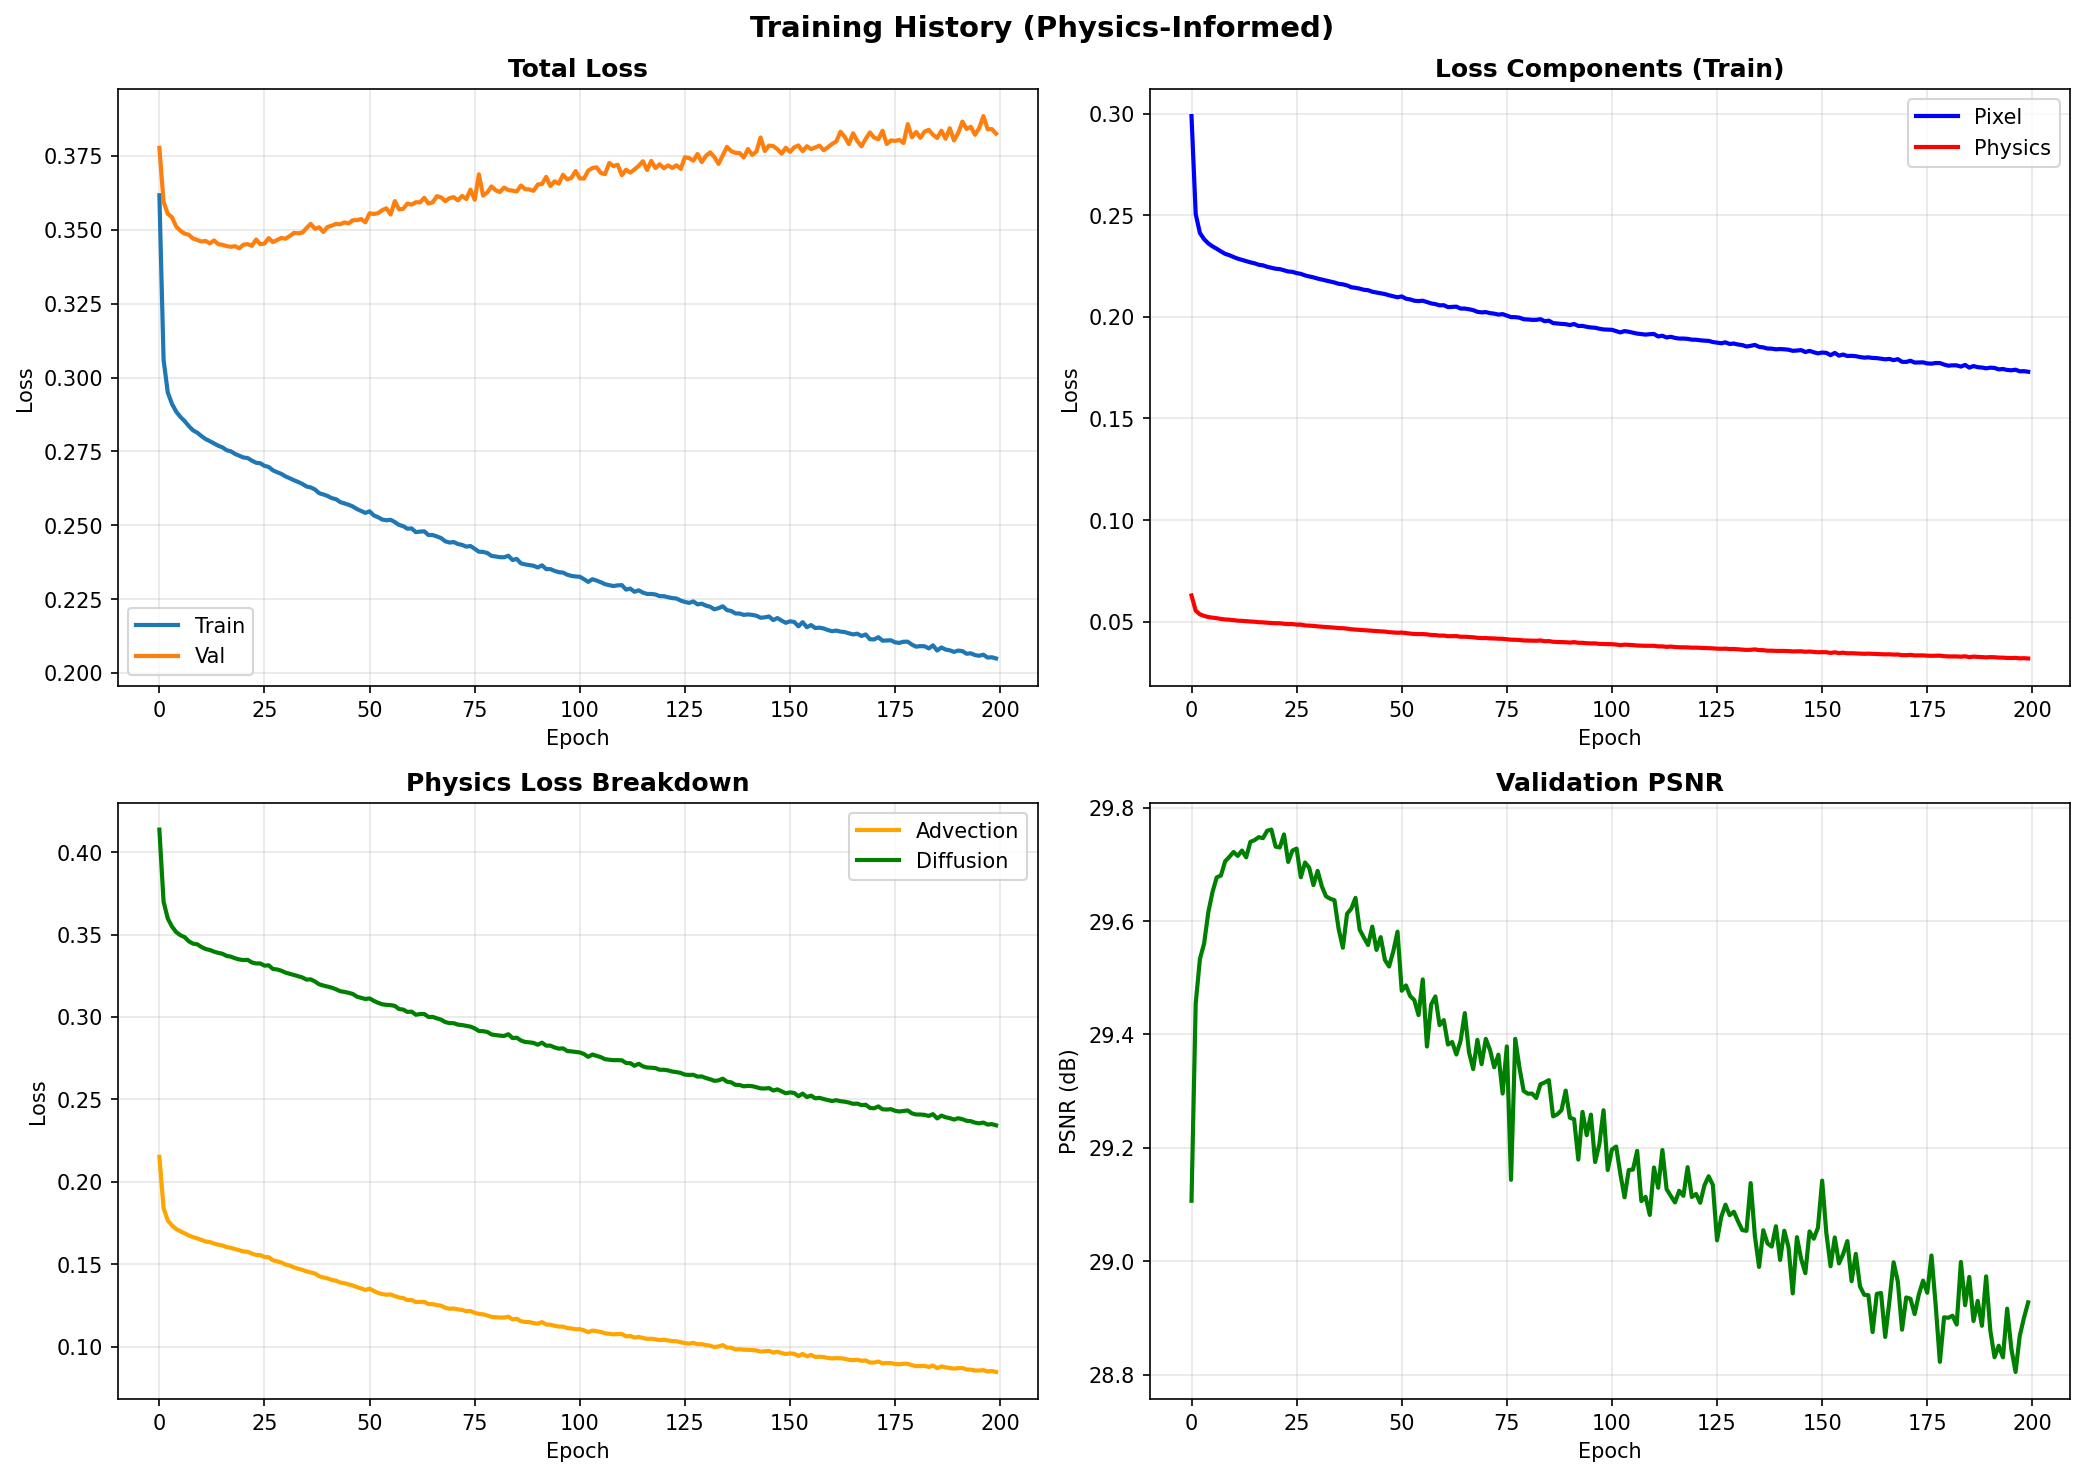

Figure saved: /workspaces/jhtdb-ml/work/SR/sr_esrgan_isotropic_ganOFF_physicsON/plots/03_training_history.png


In [29]:
if USE_PHYSICS_LOSS and USE_PHYSICS_DATASET:
    # Extended visualization with physics losses
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # Total loss
    axes[0, 0].plot(history['train_loss'], label='Train', linewidth=2)
    axes[0, 0].plot(history['val_loss'], label='Val', linewidth=2)
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Loss')
    axes[0, 0].set_title('Total Loss', fontweight='bold')
    axes[0, 0].legend()
    axes[0, 0].grid(alpha=0.3)
    
    # Loss components
    axes[0, 1].plot(history['train_loss_pixel'], label='Pixel', linewidth=2, color='blue')
    axes[0, 1].plot(history['train_loss_physics'], label='Physics', linewidth=2, color='red')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Loss')
    axes[0, 1].set_title('Loss Components (Train)', fontweight='bold')
    axes[0, 1].legend()
    axes[0, 1].grid(alpha=0.3)
    
    # Physics loss breakdown
    axes[1, 0].plot(history['train_loss_advection'], label='Advection', linewidth=2, color='orange')
    axes[1, 0].plot(history['train_loss_diffusion'], label='Diffusion', linewidth=2, color='green')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Loss')
    axes[1, 0].set_title('Physics Loss Breakdown', fontweight='bold')
    axes[1, 0].legend()
    axes[1, 0].grid(alpha=0.3)
    
    # Validation PSNR
    axes[1, 1].plot(history['val_psnr'], linewidth=2, color='green')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('PSNR (dB)')
    axes[1, 1].set_title('Validation PSNR', fontweight='bold')
    axes[1, 1].grid(alpha=0.3)
    
    plt.suptitle('Training History (Physics-Informed)', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / '03_training_history.png', bbox_inches='tight', dpi=150)
    plt.show()
    
else:
    # Standard visualization
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].plot(history['train_loss'], label='Train', linewidth=2)
    axes[0].plot(history['val_loss'], label='Val', linewidth=2)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Training and Validation Loss', fontweight='bold')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(history['val_psnr'], linewidth=2, color='green')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('PSNR (dB)')
    axes[1].set_title('Validation PSNR', fontweight='bold')
    axes[1].grid(alpha=0.3)

    plt.suptitle('Training History', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / '03_training_history.png', bbox_inches='tight', dpi=150)
    plt.show()

print(f"Figure saved: {FIGURES_DIR / '03_training_history.png'}")

## Validation Sample Evaluation

VALIDATION SAMPLE METRICS

Data ranges (normalized):
  LR input:    [ -3.765,   3.395]
  Bicubic:     [ -3.833,   3.938]
  SR (ours):   [ -6.159,   5.928]
  HR target:   [ -6.318,   6.401]

Metrics:
  Bicubic:     MAE=0.3068, PSNR=22.45 dB
  SR (ours):   MAE=0.2513, PSNR=23.99 dB
  Improvement: +1.55 dB
✓ Saved: 01_LR_input.png
✓ Saved: 02_bicubic.png
✓ Saved: 03_sr_ours.png
✓ Saved: 04_hr_target.png

✓ All figures saved to: /workspaces/jhtdb-ml/work/SR/sr_esrgan_isotropic_ganOFF_physicsON/plots
  View them individually to see fine-scale structures!

PHYSICS TERMS COMPARISON
Advection (u·∇ω) MAE:
  ML:      46.408550
  Bicubic: 53.765785
  Improvement: 13.7%

Diffusion (∇²ω) MAE:
  ML:      9086.865234
  Bicubic: 9397.726562
  Improvement: 3.3%


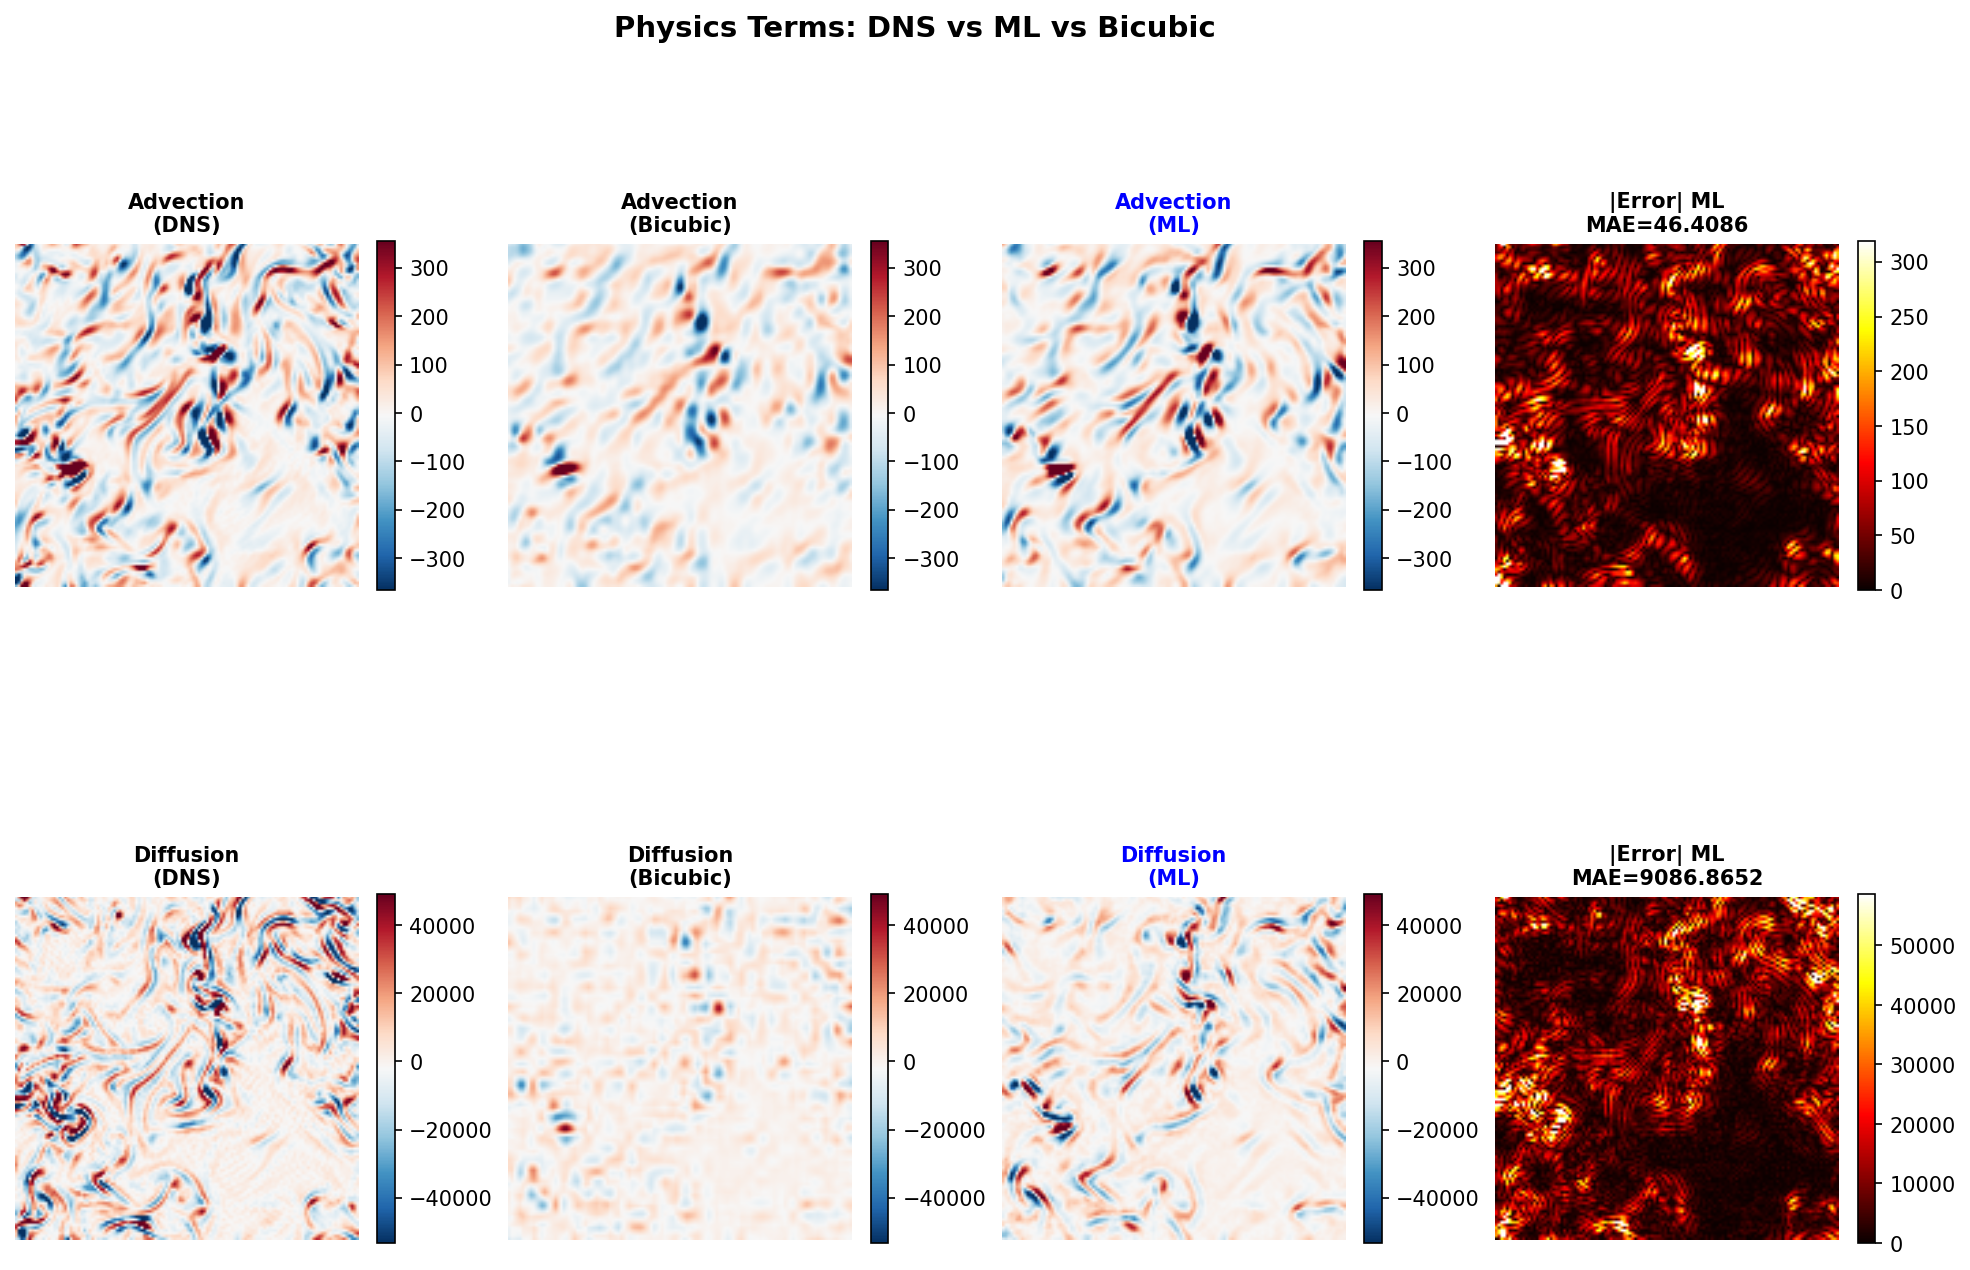


✓ Saved: /workspaces/jhtdb-ml/work/SR/sr_esrgan_isotropic_ganOFF_physicsON/plots/05_physics_comparison.png


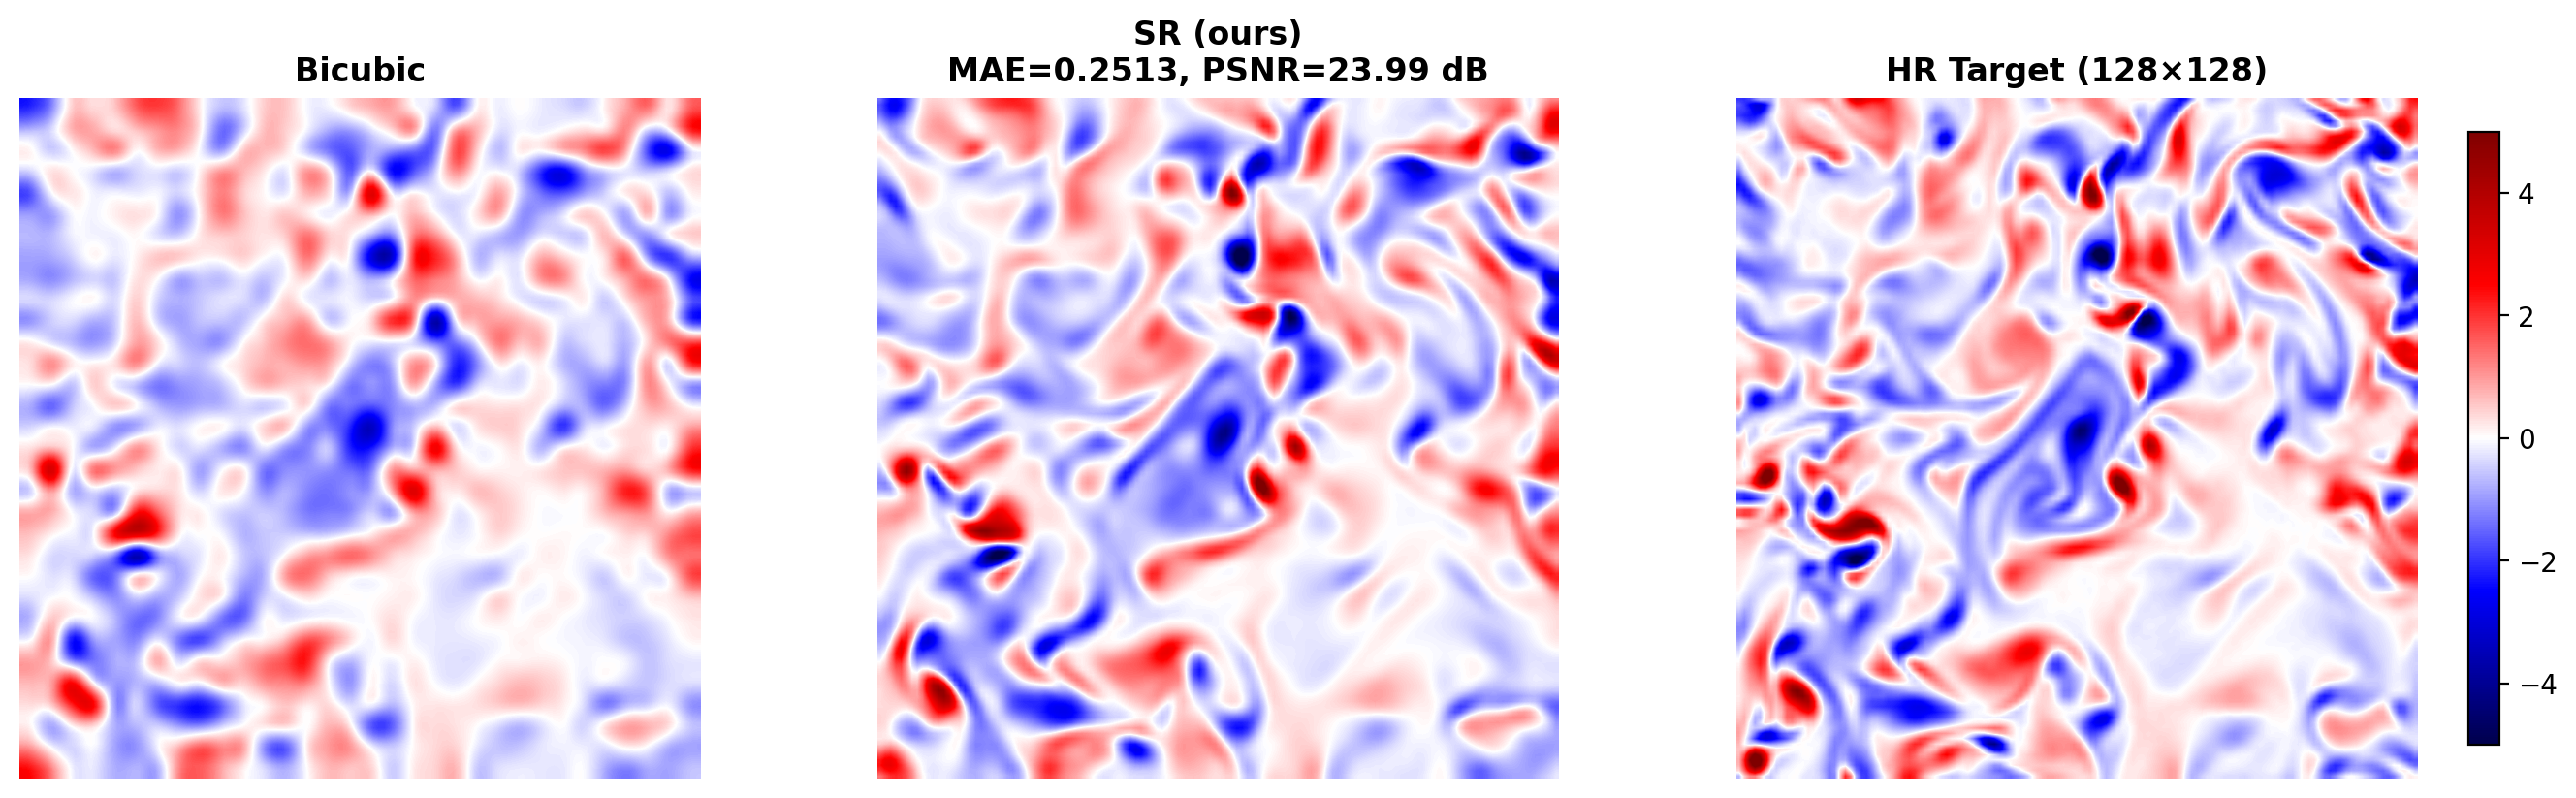

✓ Saved: 06_triptych_full.png


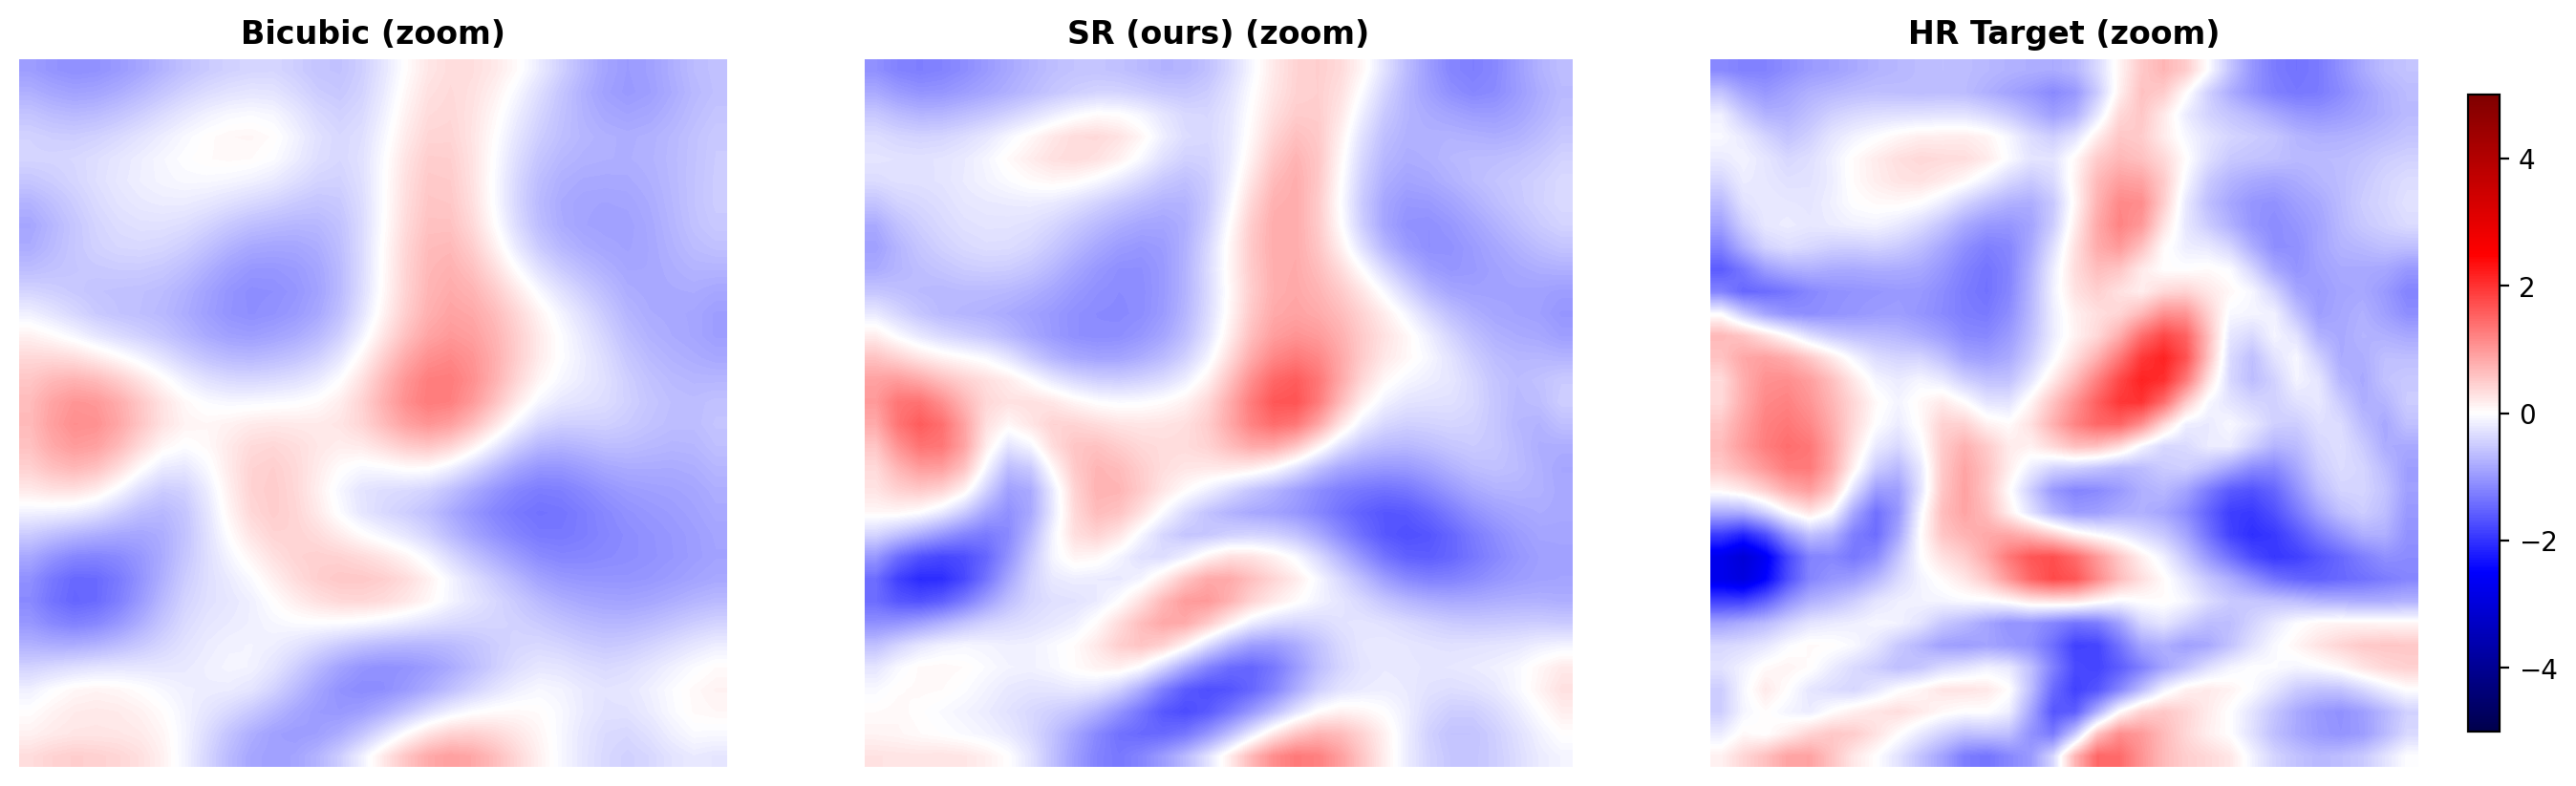

✓ Saved: 07_triptych_zoom.png (ROI: x=62:94, y=3:35)


In [30]:
# =============================================================================
# PLOT CONFIG: Model Evaluation
# =============================================================================
PLOT_CONFIG_EVAL = {
    "vmin": None,            # None for auto
    "vmax": None,
    "cmap": "seismic",
    "figsize": (12, 10),
    "dpi": 200,
}

# =============================================================================
# Load best model & pick a validation sample
# =============================================================================
model.load_state_dict(
    torch.load(
        manager.checkpoints_dir / LAST_CKPT_NAME, ## Use BEST_CKPT_NAME for best model
        map_location=DEVICE,
        weights_only=True,
    )
)
model.eval()

if USE_PHYSICS_DATASET:
    sample = val_dataset[0]
    val_lr = sample["lr_omega"]
    val_hr = sample["hr_omega"]
else:
    val_lr, val_hr = val_dataset[0]

# =============================================================================
# Predict (SR) and Bicubic baseline
# =============================================================================
with torch.no_grad():
    sr_patch = (
        model(val_lr.unsqueeze(0).to(DEVICE))
        .squeeze(0)
        .squeeze(0)
        .cpu()
    )

    # Bicubic upsample baseline
    lr_for_bicubic = val_lr if val_lr.dim() == 3 else val_lr.unsqueeze(0)
    bicubic_patch = (
        F.interpolate(
            lr_for_bicubic.unsqueeze(0),
            size=(HR_SIZE, HR_SIZE),
            mode="bicubic",
            align_corners=False,
        )
        .squeeze(0)
        .squeeze(0)
        .cpu()
    )

# =============================================================================
# Convert to numpy & compute metrics
# =============================================================================
# Note: if val_lr is (T,H,W) take the last frame; else channel-first (C,H,W) take channel 0
lr_np = val_lr[-1].numpy() if val_lr.dim() == 3 else val_lr[0].numpy()
hr_np = val_hr.numpy()
sr_np = sr_patch.numpy()
bicubic_np = bicubic_patch.numpy()

mae_sr = np.mean(np.abs(sr_np - hr_np))
mae_bicubic = np.mean(np.abs(bicubic_np - hr_np))

psnr_sr = psnr(
    torch.from_numpy(sr_np).unsqueeze(0).unsqueeze(0),
    torch.from_numpy(hr_np).unsqueeze(0).unsqueeze(0),
).item()
psnr_bicubic = psnr(
    torch.from_numpy(bicubic_np).unsqueeze(0).unsqueeze(0),
    torch.from_numpy(hr_np).unsqueeze(0).unsqueeze(0),
).item()

print("=" * 70)
print("VALIDATION SAMPLE METRICS")
print("=" * 70)
print("\nData ranges (normalized):")
print(f"  LR input:    [{lr_np.min():>7.3f}, {lr_np.max():>7.3f}]")
print(f"  Bicubic:     [{bicubic_np.min():>7.3f}, {bicubic_np.max():>7.3f}]")
print(f"  SR (ours):   [{sr_np.min():>7.3f}, {sr_np.max():>7.3f}]")
print(f"  HR target:   [{hr_np.min():>7.3f}, {hr_np.max():>7.3f}]")
print("\nMetrics:")
print(f"  Bicubic:     MAE={mae_bicubic:.4f}, PSNR={psnr_bicubic:.2f} dB")
print(f"  SR (ours):   MAE={mae_sr:.4f}, PSNR={psnr_sr:.2f} dB")
print(f"  Improvement: {psnr_sr - psnr_bicubic:+.2f} dB")
print("=" * 70)

# =============================================================================
# Save single-field figures (LR, Bicubic, SR, HR)
# =============================================================================
fields_to_plot = {
    "01_LR_input": (lr_np, f"LR Input ({LR_SIZE}×{LR_SIZE})"),
    "02_bicubic": (
        bicubic_np,
        f"Bicubic Upsampling\\nMAE={mae_bicubic:.4f}, PSNR={psnr_bicubic:.2f} dB",
    ),
    "03_sr_ours": (
        sr_np,
        f"SR Model (ours)\\nMAE={mae_sr:.4f}, PSNR={psnr_sr:.2f} dB",
    ),
    "04_hr_target": (hr_np, f"HR Ground Truth ({HR_SIZE}×{HR_SIZE})"),
}

# Color limits
vmin = (
    PLOT_CONFIG_EVAL["vmin"]
    if PLOT_CONFIG_EVAL["vmin"] is not None
    else min(arr.min() for arr, _ in fields_to_plot.values())
)
vmax = (
    PLOT_CONFIG_EVAL["vmax"]
    if PLOT_CONFIG_EVAL["vmax"] is not None
    else max(arr.max() for arr, _ in fields_to_plot.values())
)

for filename, (field, title) in fields_to_plot.items():
    fig = plt.figure(figsize=PLOT_CONFIG_EVAL["figsize"])
    im = plt.imshow(
        field.T,
        cmap=PLOT_CONFIG_EVAL["cmap"],
        origin="lower",
        vmin=vmin,
        vmax=vmax,
    )
    plt.title(title, fontsize=16, fontweight="bold", pad=20)
    plt.colorbar(im, fraction=0.046, pad=0.04)
    plt.axis("off")
    plt.tight_layout()

    save_path = FIGURES_DIR / f"{filename}.png"
    plt.savefig(save_path, bbox_inches="tight", dpi=PLOT_CONFIG_EVAL["dpi"])
    plt.close()
    print(f"\u2713 Saved: {save_path.name}")

print(f"\n\u2713 All figures saved to: {FIGURES_DIR}")
print("  View them individually to see fine-scale structures!")

# =============================================================================
# Physics Terms Comparison (DNS vs ML vs Bicubic)
# =============================================================================
if USE_PHYSICS_DATASET:
    print(f"\n{'=' * 70}")
    print("PHYSICS TERMS COMPARISON")
    print("=" * 70)

    # Velocity fields
    sample_full = val_dataset[0]
    hr_ux_np = sample_full["hr_ux"].numpy()
    hr_uy_np = sample_full["hr_uy"].numpy()

    # Helper functions (logic unchanged)
    def compute_advection_term(u, v, omega, dx, dy):
        u_t = torch.from_numpy(u).unsqueeze(0) if isinstance(u, np.ndarray) else u
        v_t = torch.from_numpy(v).unsqueeze(0) if isinstance(v, np.ndarray) else v
        omega_t = (
            torch.from_numpy(omega).unsqueeze(0)
            if isinstance(omega, np.ndarray)
            else omega
        )
        if u_t.dim() == 4:
            u_t, v_t, omega_t = u_t.squeeze(1), v_t.squeeze(1), omega_t.squeeze(1)
        domega_dx = (omega_t[:, :, 2:] - omega_t[:, :, :-2]) / (2 * dx)
        domega_dy = (omega_t[:, 2:, :] - omega_t[:, :-2, :]) / (2 * dy)
        u_c = u_t[:, 1:-1, 1:-1]
        v_c = v_t[:, 1:-1, 1:-1]
        domega_dx_c = domega_dx[:, 1:-1, :]
        domega_dy_c = domega_dy[:, :, 1:-1]
        result = u_c * domega_dx_c + v_c * domega_dy_c
        return result.squeeze(0).numpy() if hasattr(result, "numpy") else result.squeeze(0)

    def compute_diffusion_term(omega, dx, dy):
        omega_t = (
            torch.from_numpy(omega).unsqueeze(0)
            if isinstance(omega, np.ndarray)
            else omega
        )
        if omega_t.dim() == 4:
            omega_t = omega_t.squeeze(1)
        d2omega_dx2 = (
            omega_t[:, :, 2:] - 2 * omega_t[:, :, 1:-1] + omega_t[:, :, :-2]
        ) / (dx**2)
        d2omega_dy2 = (
            omega_t[:, 2:, :] - 2 * omega_t[:, 1:-1, :] + omega_t[:, :-2, :]
        ) / (dy**2)
        d2omega_dx2_c = d2omega_dx2[:, 1:-1, :]
        d2omega_dy2_c = d2omega_dy2[:, :, 1:-1]
        result = d2omega_dx2_c + d2omega_dy2_c
        return result.squeeze(0).numpy() if hasattr(result, "numpy") else result.squeeze(0)

    # Compute physics terms
    adv_dns = compute_advection_term(hr_ux_np, hr_uy_np, hr_np, dx, dy)
    diff_dns = compute_diffusion_term(hr_np, dx, dy)

    adv_ml = compute_advection_term(hr_ux_np, hr_uy_np, sr_np, dx, dy)
    diff_ml = compute_diffusion_term(sr_np, dx, dy)

    adv_bicubic = compute_advection_term(hr_ux_np, hr_uy_np, bicubic_np, dx, dy)
    diff_bicubic = compute_diffusion_term(bicubic_np, dx, dy)

    # Errors
    adv_error_ml = np.abs(adv_ml - adv_dns)
    diff_error_ml = np.abs(diff_ml - diff_dns)
    adv_error_bicubic = np.abs(adv_bicubic - adv_dns)
    diff_error_bicubic = np.abs(diff_bicubic - diff_dns)

    print("Advection (u·∇ω) MAE:")
    print(f"  ML:      {np.mean(adv_error_ml):.6f}")
    print(f"  Bicubic: {np.mean(adv_error_bicubic):.6f}")
    print(
        f"  Improvement: {(1 - np.mean(adv_error_ml) / np.mean(adv_error_bicubic)) * 100:.1f}%"
    )

    print("\nDiffusion (∇²ω) MAE:")
    print(f"  ML:      {np.mean(diff_error_ml):.6f}")
    print(f"  Bicubic: {np.mean(diff_error_bicubic):.6f}")
    print(
        f"  Improvement: {(1 - np.mean(diff_error_ml) / np.mean(diff_error_bicubic)) * 100:.1f}%"
    )

    # Comparison figure
    fig = plt.figure(figsize=(16, 10))
    gs = fig.add_gridspec(2, 4, hspace=0.3, wspace=0.3)

    # Percentile clipping
    adv_vmin, adv_vmax = np.percentile(adv_dns, [1, 99])
    diff_vmin, diff_vmax = np.percentile(diff_dns, [1, 99])

    # Row 1: Advection
    ax = fig.add_subplot(gs[0, 0])
    im = ax.imshow(adv_dns.T, cmap="RdBu_r", origin="lower", vmin=adv_vmin, vmax=adv_vmax, interpolation="bilinear")
    ax.set_title("Advection\n(DNS)", fontsize=10, fontweight="bold")
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046)

    ax = fig.add_subplot(gs[0, 1])
    im = ax.imshow(adv_bicubic.T, cmap="RdBu_r", origin="lower", vmin=adv_vmin, vmax=adv_vmax, interpolation="bilinear")
    ax.set_title("Advection\n(Bicubic)", fontsize=10, fontweight="bold")
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046)

    ax = fig.add_subplot(gs[0, 2])
    im = ax.imshow(adv_ml.T, cmap="RdBu_r", origin="lower", vmin=adv_vmin, vmax=adv_vmax, interpolation="bilinear")
    ax.set_title("Advection\n(ML)", fontsize=10, fontweight="bold", color="blue")
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046)

    ax = fig.add_subplot(gs[0, 3])
    err_max = max(np.percentile(adv_error_ml, 99), np.percentile(adv_error_bicubic, 99))
    im = ax.imshow(adv_error_ml.T, cmap="hot", origin="lower", vmin=0, vmax=err_max, interpolation="bilinear")
    ax.set_title(f"|Error| ML\nMAE={np.mean(adv_error_ml):.4f}", fontsize=10, fontweight="bold")
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046)

    # Row 2: Diffusion
    ax = fig.add_subplot(gs[1, 0])
    im = ax.imshow(diff_dns.T, cmap="RdBu_r", origin="lower", vmin=diff_vmin, vmax=diff_vmax, interpolation="bilinear")
    ax.set_title("Diffusion\n(DNS)", fontsize=10, fontweight="bold")
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046)

    ax = fig.add_subplot(gs[1, 1])
    im = ax.imshow(diff_bicubic.T, cmap="RdBu_r", origin="lower", vmin=diff_vmin, vmax=diff_vmax, interpolation="bilinear")
    ax.set_title("Diffusion\n(Bicubic)", fontsize=10, fontweight="bold")
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046)

    ax = fig.add_subplot(gs[1, 2])
    im = ax.imshow(diff_ml.T, cmap="RdBu_r", origin="lower", vmin=diff_vmin, vmax=diff_vmax, interpolation="bilinear")
    ax.set_title("Diffusion\n(ML)", fontsize=10, fontweight="bold", color="blue")
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046)

    ax = fig.add_subplot(gs[1, 3])
    err_max = max(np.percentile(diff_error_ml, 99), np.percentile(diff_error_bicubic, 99))
    im = ax.imshow(diff_error_ml.T, cmap="hot", origin="lower", vmin=0, vmax=err_max, interpolation="bilinear")
    ax.set_title(f"|Error| ML\nMAE={np.mean(diff_error_ml):.4f}", fontsize=10, fontweight="bold")
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046)

    plt.suptitle("Physics Terms: DNS vs ML vs Bicubic", fontsize=14, fontweight="bold")
    plt.savefig(FIGURES_DIR / "05_physics_comparison.png", bbox_inches="tight", dpi=150)
    plt.show()
    print(f"\n\u2713 Saved: {FIGURES_DIR / '05_physics_comparison.png'}")

# =============================================================================
# ADDITIONAL COMPARISON FIGURES: FULL-FIELD AND RANDOM ZOOM
# =============================================================================
# Simple plotting knobs (edit these only)
VMIN, VMAX = -5, 5
CMAP = PLOT_CONFIG_EVAL["cmap"]
DPI = PLOT_CONFIG_EVAL["dpi"]
ZOOM_FRAC = 0.25
SEED = 200  # set to an int for reproducible zoom; use None to randomize

# RNG for reproducible zoom crops
_rng = np.random.default_rng(SEED) if SEED is not None else np.random.default_rng()

vmin_common = VMIN
vmax_common = VMAX

# Figure 1: Full-field triptych
fig1, axes1 = plt.subplots(1, 3, figsize=(14, 4), dpi=DPI, constrained_layout=True)
triptych = [
    (bicubic_np, "Bicubic"),
    (sr_np, f"SR (ours)\nMAE={mae_sr:.4f}, PSNR={psnr_sr:.2f} dB"),
    (hr_np, f"HR Target ({HR_SIZE}×{HR_SIZE})"),
]

im_last = None
for ax, (field, title) in zip(axes1, triptych):
    im_last = ax.imshow(
        field.T,
        cmap=CMAP,
        origin="lower",
        vmin=vmin_common,
        vmax=vmax_common,
        interpolation="bilinear"
    )
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.axis("off")

fig1.colorbar(im_last, ax=axes1, location="right", shrink=0.9, pad=0.02)
save_path_full = FIGURES_DIR / "06_triptych_full.png"
fig1.savefig(save_path_full, bbox_inches="tight", dpi=DPI)
plt.show()
print(f"\u2713 Saved: {save_path_full.name}")

# Figure 2: Random zoom triptych
zoom_size = max(8, int(HR_SIZE * ZOOM_FRAC))
y0 = _rng.integers(0, HR_SIZE - zoom_size + 1)
x0 = _rng.integers(0, HR_SIZE - zoom_size + 1)


def crop(arr, y, x, sz):
    return arr[y : y + sz, x : x + sz]


bicubic_zoom = crop(bicubic_np, y0, x0, zoom_size)
sr_zoom = crop(sr_np, y0, x0, zoom_size)
hr_zoom = crop(hr_np, y0, x0, zoom_size)

fig2, axes2 = plt.subplots(1, 3, figsize=(14, 4), dpi=DPI, constrained_layout=True)
triptych_zoom = [
    (bicubic_zoom, "Bicubic (zoom)"),
    (sr_zoom, "SR (ours) (zoom)"),
    (hr_zoom, "HR Target (zoom)"),
]

im_last = None
for ax, (field, title) in zip(axes2, triptych_zoom):
    im_last = ax.imshow(
        field.T,
        cmap=CMAP,
        origin="lower",
        vmin=vmin_common,
        vmax=vmax_common,
        interpolation="bilinear"
    )
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.axis("off")

fig2.colorbar(im_last, ax=axes2, location="right", shrink=0.9, pad=0.02)
save_path_zoom = FIGURES_DIR / "07_triptych_zoom.png"
fig2.savefig(save_path_zoom, bbox_inches="tight", dpi=DPI)
plt.show()
print(
    f"\u2713 Saved: {save_path_zoom.name} (ROI: x={x0}:{x0 + zoom_size}, y={y0}:{y0 + zoom_size})"
)

## Load Previous History (Optional)

## Load and Replot Previous Training History (Optional)

Load training history from a previous run and replot the curves for comparison.

In [18]:
# =============================================================================
# Load and replot training history from a previous run
# =============================================================================

# Path to previous training history
PREV_HISTORY_PATH = ROOT / 'work/SR/sr_edsr_isotropic_20251110_075438/training_history.json'

if PREV_HISTORY_PATH.exists():
    print(f"Loading previous training history from:")
    print(f"  {PREV_HISTORY_PATH}")
    
    with open(PREV_HISTORY_PATH, 'r') as fp:
        prev_history = json.load(fp)
    
    print(f"\nPrevious run statistics:")
    print(f"  Epochs trained: {len(prev_history['train_loss'])}")
    print(f"  Best val loss: {min(prev_history['val_loss']):.4f}")
    print(f"  Best val PSNR: {max(prev_history['val_psnr']):.2f} dB")
    print(f"  Final train loss: {prev_history['train_loss'][-1]:.4f}")
    print(f"  Final val loss: {prev_history['val_loss'][-1]:.4f}")
    print(f"  Final val PSNR: {prev_history['val_psnr'][-1]:.2f} dB")
    
    # Check if physics-informed training was used
    has_physics = 'train_loss_physics' in prev_history and any(prev_history['train_loss_physics'])
    
    if has_physics:
        # Extended visualization with physics losses
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        
        # Total loss
        axes[0, 0].plot(prev_history['train_loss'], label='Train', linewidth=2, color='blue')
        axes[0, 0].plot(prev_history['val_loss'], label='Val', linewidth=2, color='orange')
        axes[0, 0].set_xlabel('Epoch', fontsize=11)
        axes[0, 0].set_ylabel('Loss', fontsize=11)
        axes[0, 0].set_title('Total Loss (Previous Run)', fontweight='bold', fontsize=12)
        axes[0, 0].legend()
        axes[0, 0].grid(alpha=0.3)
        
        # Loss components
        axes[0, 1].plot(prev_history['train_loss_pixel'], label='Pixel', linewidth=2, color='blue')
        axes[0, 1].plot(prev_history['train_loss_physics'], label='Physics', linewidth=2, color='red')
        axes[0, 1].set_xlabel('Epoch', fontsize=11)
        axes[0, 1].set_ylabel('Loss', fontsize=11)
        axes[0, 1].set_title('Loss Components (Train)', fontweight='bold', fontsize=12)
        axes[0, 1].legend()
        axes[0, 1].grid(alpha=0.3)
        
        # Physics loss breakdown
        axes[1, 0].plot(prev_history['train_loss_advection'], label='Advection', linewidth=2, color='orange')
        axes[1, 0].plot(prev_history['train_loss_diffusion'], label='Diffusion', linewidth=2, color='green')
        axes[1, 0].set_xlabel('Epoch', fontsize=11)
        axes[1, 0].set_ylabel('Loss', fontsize=11)
        axes[1, 0].set_title('Physics Loss Breakdown', fontweight='bold', fontsize=12)
        axes[1, 0].legend()
        axes[1, 0].grid(alpha=0.3)
        
        # Validation PSNR
        axes[1, 1].plot(prev_history['val_psnr'], linewidth=2, color='green')
        axes[1, 1].set_xlabel('Epoch', fontsize=11)
        axes[1, 1].set_ylabel('PSNR (dB)', fontsize=11)
        axes[1, 1].set_title('Validation PSNR', fontweight='bold', fontsize=12)
        axes[1, 1].grid(alpha=0.3)
        
        plt.suptitle('Previous Training History (Physics-Informed)', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / '03b_previous_training_history.png', bbox_inches='tight', dpi=150)
        plt.show()
        
    else:
        # Standard visualization
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        axes[0].plot(prev_history['train_loss'], label='Train', linewidth=2, color='blue')
        axes[0].plot(prev_history['val_loss'], label='Val', linewidth=2, color='orange')
        axes[0].set_xlabel('Epoch', fontsize=12)
        axes[0].set_ylabel('Loss', fontsize=12)
        axes[0].set_title('Training and Validation Loss (Previous Run)', fontweight='bold', fontsize=13)
        axes[0].legend(fontsize=11)
        axes[0].grid(alpha=0.3)

        axes[1].plot(prev_history['val_psnr'], linewidth=2, color='green')
        axes[1].set_xlabel('Epoch', fontsize=12)
        axes[1].set_ylabel('PSNR (dB)', fontsize=12)
        axes[1].set_title('Validation PSNR (Previous Run)', fontweight='bold', fontsize=13)
        axes[1].grid(alpha=0.3)

        plt.suptitle(f'Previous Training History ({len(prev_history["train_loss"])} epochs)', 
                     fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / '03b_previous_training_history.png', bbox_inches='tight', dpi=150)
        plt.show()

    print(f"\n✓ Figure saved: {FIGURES_DIR / '03b_previous_training_history.png'}")
    
else:
    print(f"Previous history file not found:")
    print(f"  {PREV_HISTORY_PATH}")
    print(f"\nSkipping previous history visualization.")

Previous history file not found:
  /workspaces/jhtdb-ml/work/SR/sr_edsr_isotropic_20251110_075438/training_history.json

Skipping previous history visualization.


## Save Model and Metadata

In [19]:
# Save to saved_models directory
MODEL_SAVE_DIR = ROOT / 'saved_models/SR'
MODEL_SAVE_DIR.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
model_name = f"{config['model']['architecture']}_x{config['model']['scale_factor']}_{timestamp}"
model_path = MODEL_SAVE_DIR / f"{model_name}.pth"

# Save model state dict
torch.save(model.state_dict(), model_path)

# Create comprehensive metadata
metadata = {
    'model_name': model_name,
    'architecture': config['model']['architecture'],
    'scale_factor': config['model']['scale_factor'],
    'component': component,
    'input_size': [N_FRAMES, LR_SIZE, LR_SIZE],
    'output_size': [HR_SIZE, HR_SIZE],
    'parameters': int(param_count),
    'epochs': int(config['training']['epochs']),
    'best_val_loss': float(min(history['val_loss'])),
    'best_val_psnr': float(max(history['val_psnr'])),
    'experiment_dir': str(manager.run_dir),
    'dataset': str(h5_path),
    'config_file': str(CONFIG_PATH),
    'data_split': {
        'train_snapshots': len(train_idx),
        'val_snapshots': len(val_idx),
        'test_snapshots': len(test_idx),
        'split_method': 'snapshot-wise (temporal order preserved)'
    },
    'temporal_stacking': {
        'enabled': config['data']['temporal']['enabled'],
        'num_frames': N_FRAMES
    },
    'augmentation': {
        'enabled': config['data']['augmentation']['enabled'],
        'methods': list(config['data']['augmentation'].keys()) if config['data']['augmentation']['enabled'] else []
    },
    'normalization': config['data']['normalization']['method']
}

metadata_path = MODEL_SAVE_DIR / f"{model_name}_metadata.json"
with open(metadata_path, 'w') as fp:
    json.dump(metadata, fp, indent=2)

print(f"\n{'='*70}")
print(f"MODEL SAVED")
print(f"{'='*70}")
print(f"  Weights: {model_path}")
print(f"  Metadata: {metadata_path}")
print(f"\nModel can be loaded with:")
print(f"  from models.factory import build_model_from_config")
print(f"  model = build_model_from_config(config['model'], {LR_SIZE}, {HR_SIZE})")
print(f"  model.load_state_dict(torch.load('{model_path}'))")
print(f"{'='*70}")


MODEL SAVED
  Weights: /workspaces/jhtdb-ml/saved_models/SR/esrgan_x4_20251127_065454.pth
  Metadata: /workspaces/jhtdb-ml/saved_models/SR/esrgan_x4_20251127_065454_metadata.json

Model can be loaded with:
  from models.factory import build_model_from_config
  model = build_model_from_config(config['model'], 32, 128)
  model.load_state_dict(torch.load('/workspaces/jhtdb-ml/saved_models/SR/esrgan_x4_20251127_065454.pth'))
